# 06 — Optimization and Regularization in Deep Learning

### Training faster, generalizing better: tested on yeast proteins and tumour gene expression

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 06 of 12  
**Level:** Intermediate → advanced  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Datasets:** UCI *Yeast* (small, 8 features, 10 imbalanced classes) and UCI *Gene expression cancer RNA-Seq* (801 tumours, 20,531 genes, 5 cancer types)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Relate **epochs, batches, and iterations**, and show that the mini-batch gradient is an unbiased estimator whose variance shrinks like $1/B$.
2. Explain the **stability condition** $\eta < 2/\lambda_{\max}$ for the learning rate, and use schedules (step, exponential, cosine, warm-up).
3. Write the update rules of **SGD, momentum, RMSprop, and Adam**, derive Adam's bias correction, implement all four from scratch, and verify them against Keras.
4. Derive **L2 regularization** (weight decay, ridge shrinkage, Gaussian prior) and **L1 regularization** (soft-thresholding, sparsity, Laplace prior).
5. Derive **inverted Dropout**, show it acts like an adaptive L2 penalty for linear models, and verify the formula by simulation.
6. Write the **batch normalization** equations, verify them against Keras, and explain the difference between training and inference behaviour.
7. Interpret **early stopping** as implicit regularization and read **learning curves** to diagnose overfitting.
8. Run **controlled, multi-seed experiments** on two very different biological datasets, and decide which techniques matter for which kind of problem.

> **What is new compared with Notebooks 04–05?** There we *observed* overfitting and collinearity. Here we study the tools that control them — first mathematically, with from-scratch implementations that we check against Keras, then experimentally on a **low-dimensional** dataset (Yeast: few features, ~1,000 training samples) and a **high-dimensional** one (gene expression: thousands of features, a few hundred samples).

## 1. Why optimization and regularization?

Training a network means minimizing the **empirical risk**

$$
\hat{R}(\theta) = \frac{1}{N}\sum_{i=1}^{N} \ell\big(f_\theta(x_i), y_i\big)
\qquad\text{(+ a penalty, see below)} ,
$$

but what we actually care about is the **true risk** $R(\theta) = \mathbb{E}[\ell(f_\theta(X), Y)]$ on new data. Two separate problems arise:

| Problem | Question | Tools in this notebook |
|---|---|---|
| **Optimization** | How do we find a good minimum of $\hat{R}$ quickly and reliably? | batch size, learning rate and schedules, momentum, RMSprop, Adam |
| **Generalization** | How do we keep $R(\theta)$ close to $\hat{R}(\theta)$? | L2, L1, Dropout, batch normalization, early stopping |

The two interact: the optimizer decides *which* of the many parameter settings that fit the training data we end up with, and regularization changes what "fit" means.

### 1.1 The two datasets and why we use both

| | Yeast (Notebook 04) | Gene expression (new) |
|---|---|---|
| Samples | 1,484 proteins | 801 tumours |
| Features | 8 | 20,531 genes |
| Classes | 10, strongly imbalanced | 5, moderately imbalanced |
| Challenge | little information per sample, overlapping classes | **far more features than samples** ($p \gg n$) |
| Typical overfitting | moderate, after some epochs | easy to memorize the training set |

Regularization is not one recipe: what helps in one regime may be irrelevant in the other. Running the same toolbox on both makes this visible.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend. Select the backend **before** importing Keras.

**Runtime.** The experiments train many small networks (several seeds per configuration). On a normal CPU the whole notebook takes roughly 15–30 minutes. Set `QUICK_MODE = True` in the next cell to run one seed and fewer epochs (about 4× faster) while reading the notebook for the first time.

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time, tarfile, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                     # True: 1 seed and ~40% of the epochs (for a first quick read)
N_SEEDS = 1 if QUICK_MODE else 3
EPOCH_SCALE = 0.4 if QUICK_MODE else 1.0
def epochs_for(n):                     # scale epoch budgets in quick mode
    return max(10, int(round(n * EPOCH_SCALE)))

ARTIFACT_DIR = "artifacts_06"
FIG_DIR = "figures_06"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| pandas:", pd.__version__)
print("Seeds per configuration:", N_SEEDS, "| quick mode:", QUICK_MODE)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | pandas: 2.3.3
Seeds per configuration: 3 | quick mode: False


 ## 3. Visual style

The same palette and plotting defaults as the previous notebooks. Each optimizer and each regularization technique keeps **one fixed colour** throughout the notebook.

In [2]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}
OPT_COLORS = {"SGD": COLORS["gray"], "Momentum": COLORS["purple"], "RMSprop": COLORS["green"], "Adam": COLORS["blue"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Part I — The mathematics of optimization and regularization

## 4. Epochs, batches, and iterations

Let the training set have $N$ samples and let the **batch size** be $B$.

- An **iteration** (or step) computes the gradient on one mini-batch and updates the parameters once.
- An **epoch** is one pass over the whole training set: $\lceil N/B \rceil$ iterations.
- The total number of updates is $\text{iterations} = \lceil N/B \rceil \times \text{epochs}$.

Example: $N = 1038$ (our Yeast training set) and $B = 32$ gives $\lceil 1038/32 \rceil = 33$ iterations per epoch.

### 4.1 The mini-batch gradient is unbiased

The full-batch gradient is $g = \frac{1}{N}\sum_{i} g_i$ with per-sample gradients $g_i = \nabla_\theta \ell_i$. A mini-batch $S$ of size $B$ drawn uniformly without replacement gives $g_S = \frac{1}{B}\sum_{i \in S} g_i$. Then

$$
\mathbb{E}[g_S] = g
\qquad\text{and}\qquad
\mathbb{E}\,\lVert g_S - g \rVert^2 = \frac{\operatorname{tr}\Sigma}{B}\cdot\frac{N - B}{N - 1},
\qquad
\Sigma = \frac{1}{N}\sum_i (g_i - g)(g_i - g)^{\top} .
$$

So the mini-batch gradient points in the right direction on average, and its **noise variance decreases like $1/B$** (the second factor, the finite-population correction, equals 1 for $B = 1$ and 0 for $B = N$). The noise standard deviation therefore decreases only like $1/\sqrt{B}$: quadrupling the batch size halves the noise.

### 4.2 Trade-offs of the batch size

| Small batch | Large batch |
|---|---|
| noisy gradients (can help escape sharp minima and acts as mild regularization) | accurate gradients |
| many cheap updates per epoch | few updates per epoch (more efficient on GPUs) |
| batch normalization statistics are noisy | batch statistics are reliable |

Let us verify the variance formula on a synthetic least-squares problem, where per-sample gradients are known exactly: $g_i = 2 z_i (z_i^{\top} w - y_i)$.

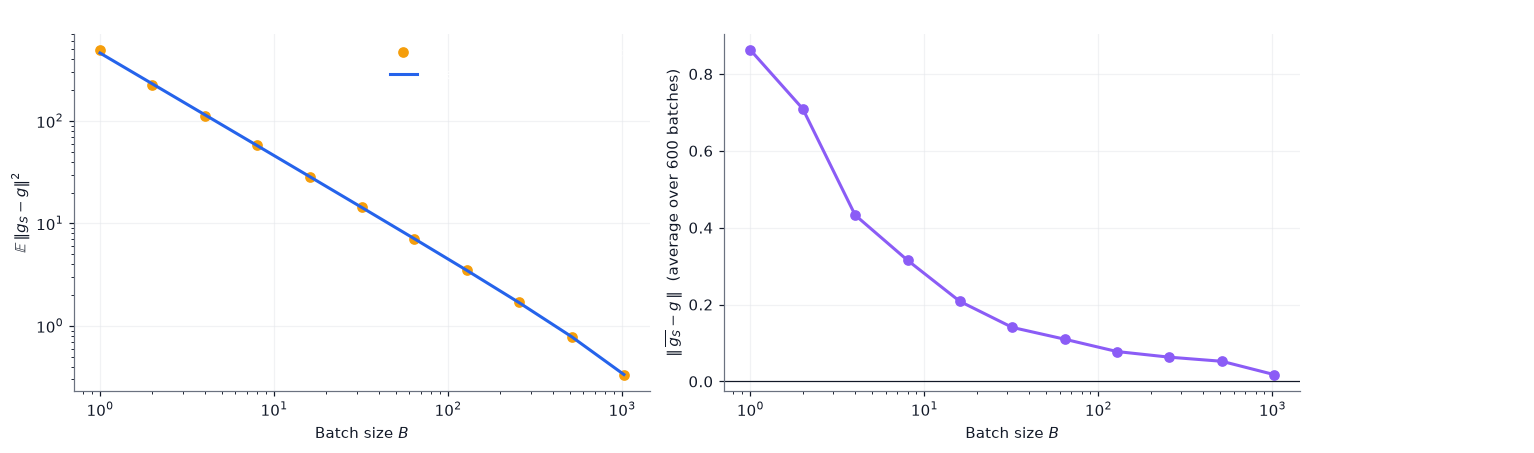

Ratio measured / theory: [1.07 0.98 0.96 1.01 0.99 1.02 1.   1.01 1.01 0.99 1.  ]


In [3]:
rng = np.random.default_rng(0)
N_syn, d_syn = 4000, 10
Z_syn = rng.normal(size=(N_syn, d_syn))
y_syn = Z_syn @ rng.normal(size=d_syn) + rng.normal(0, 1.0, size=N_syn)
w_probe = rng.normal(size=d_syn)                                    # a point where we measure gradient noise

per_sample_grads = 2 * Z_syn * (Z_syn @ w_probe - y_syn)[:, None]  # (N, d): g_i
full_grad = per_sample_grads.mean(axis=0)
trace_sigma = np.mean(np.sum((per_sample_grads - full_grad) ** 2, axis=1))

batch_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
empirical, theory, bias_norm = [], [], []
for B in batch_sizes:
    deviations, means = [], []
    for _ in range(600):
        idx = rng.choice(N_syn, size=B, replace=False)
        g_batch = per_sample_grads[idx].mean(axis=0)
        deviations.append(np.sum((g_batch - full_grad) ** 2)); means.append(g_batch)
    empirical.append(np.mean(deviations))
    theory.append(trace_sigma / B * (N_syn - B) / (N_syn - 1))
    bias_norm.append(np.linalg.norm(np.mean(means, axis=0) - full_grad))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].loglog(batch_sizes, empirical, "o", color=COLORS["orange"], label="Measured (600 batches each)")
axes[0].loglog(batch_sizes, theory, "-", color=COLORS["blue"], label=r"Theory: $\frac{\mathrm{tr}\,\Sigma}{B}\,\frac{N-B}{N-1}$")
axes[0].set_xlabel("Batch size $B$"); axes[0].set_ylabel(r"$\mathbb{E}\,\|g_S - g\|^2$")
axes[0].set_title("Gradient noise falls like 1/B"); axes[0].legend()
axes[1].semilogx(batch_sizes, bias_norm, "o-", color=COLORS["purple"])
axes[1].axhline(0, color=COLORS["dark"], linewidth=0.8)
axes[1].set_xlabel("Batch size $B$"); axes[1].set_ylabel(r"$\|\,\overline{g_S} - g\,\|$  (average over 600 batches)")
axes[1].set_title("The mini-batch gradient is unbiased (the average error is only sampling noise)")
finish(fig, "01_batch_gradient_noise")
print("Ratio measured / theory:", np.round(np.array(empirical) / np.array(theory), 2))

## 5. The learning rate

### 5.1 The one-dimensional picture

For the quadratic loss $L(w) = \tfrac{1}{2}\lambda w^2$ (curvature $\lambda > 0$), gradient descent gives

$$
w_{t+1} = w_t - \eta \lambda w_t = (1 - \eta\lambda)\, w_t
\quad\Longrightarrow\quad
w_t = (1-\eta\lambda)^t\, w_0 .
$$

| Learning rate | Factor $1 - \eta\lambda$ | Behaviour |
|---|---|---|
| $\eta \ll 1/\lambda$ | slightly below 1 | converges, but slowly |
| $\eta = 1/\lambda$ | 0 | converges in one step (the optimum for this loss) |
| $1/\lambda < \eta < 2/\lambda$ | between $-1$ and 0 | converges with oscillation |
| $\eta > 2/\lambda$ | below $-1$ | **diverges** |

For a general loss, the same argument applies along each eigendirection of the Hessian, giving the **stability condition** $\eta < 2/\lambda_{\max}$ (Notebook 05, Section 9.3). The ideal learning rate for the flat directions would be large, but the steepest direction forbids it: this is the *conditioning* problem, and the reason momentum and adaptive methods exist.

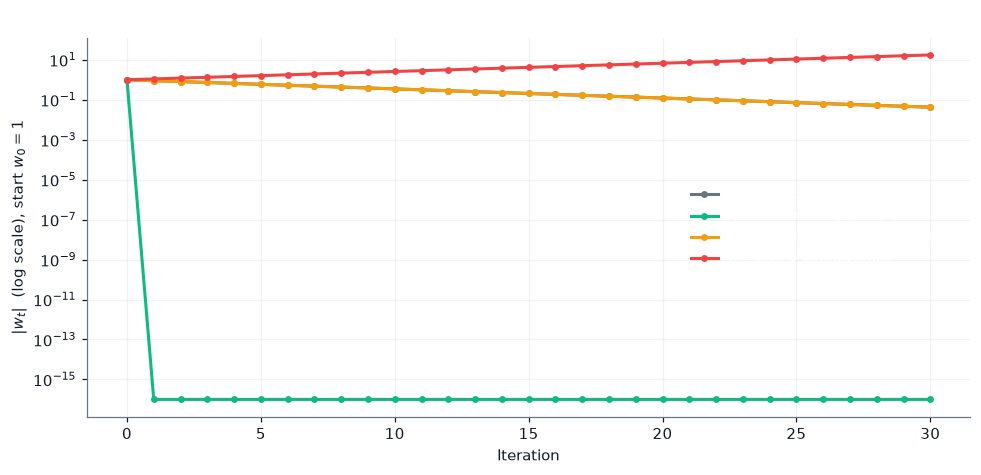

In [4]:
lam = 1.0
steps = np.arange(0, 31)
fig, ax = plt.subplots(figsize=(9, 4.4))
for eta, color, label in [(0.1, COLORS["gray"], r"$\eta=0.1$: too small, slow"),
                          (1.0, COLORS["green"], r"$\eta=1.0$: one step ($=1/\lambda$)"),
                          (1.9, COLORS["orange"], r"$\eta=1.9$: oscillates, still converges"),
                          (2.1, COLORS["red"], r"$\eta=2.1$: $>2/\lambda$, diverges")]:
    trajectory = np.abs((1 - eta * lam) ** steps) + 1e-16
    ax.semilogy(steps, trajectory, color=color, label=label, marker="o", markersize=3.5)
ax.set_xlabel("Iteration"); ax.set_ylabel(r"$|w_t|$  (log scale), start $w_0 = 1$")
ax.set_title(r"Gradient descent on $\frac{1}{2}\lambda w^2$ with $\lambda = 1$")
ax.legend(loc="center right")
finish(fig, "02_learning_rate_1d")

### 5.2 Learning-rate schedules

A large rate is useful early (fast progress), a small rate late (settling into a minimum without bouncing). A **schedule** changes $\eta_t$ during training. With $t$ the iteration and $T$ the total number of iterations:

| Schedule | Formula |
|---|---|
| Step decay | $\eta_t = \eta_0\,\gamma^{\lfloor t/s \rfloor}$ (multiply by $\gamma$ every $s$ steps) |
| Exponential decay | $\eta_t = \eta_0\,\gamma^{t/s}$ |
| Cosine decay | $\eta_t = \eta_{\min} + \tfrac{1}{2}(\eta_0 - \eta_{\min})\big(1 + \cos(\pi t / T)\big)$ |
| Linear warm-up | $\eta_t = \eta_0\,\min(1, t/T_{w})$ (very small rates at first, useful with adaptive optimizers and large models) |

A different mechanism, `ReduceLROnPlateau`, reduces the rate when a monitored metric stops improving (Notebook 03). Below we compute the schedules ourselves and check two of them against the Keras implementations.

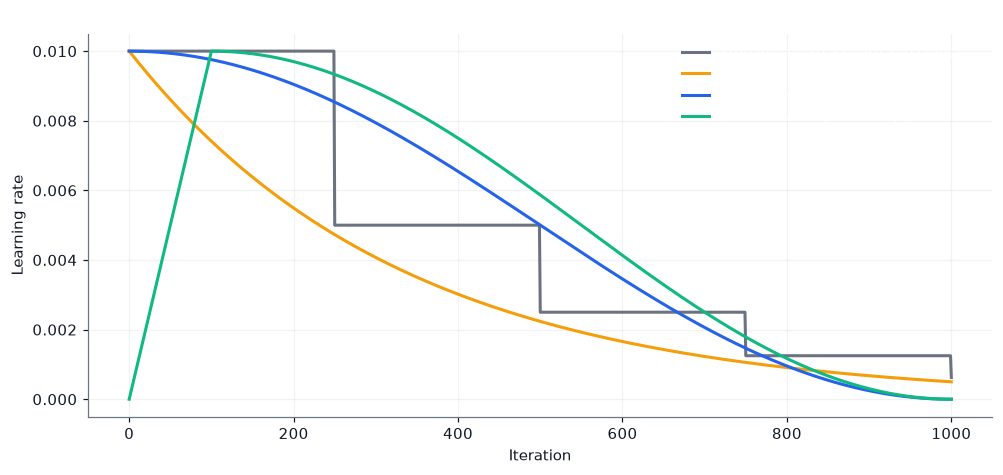

step    0: exponential  ours=0.010000 keras=0.010000 | cosine  ours=0.010000 keras=0.010000
step  250: exponential  ours=0.004729 keras=0.004729 | cosine  ours=0.008536 keras=0.008536
step  500: exponential  ours=0.002236 keras=0.002236 | cosine  ours=0.005000 keras=0.005000
step 1000: exponential  ours=0.000500 keras=0.000500 | cosine  ours=0.000000 keras=0.000000


In [5]:
T = 1000
t = np.arange(T + 1)
eta0 = 1e-2

step_decay = eta0 * 0.5 ** (t // 250)
exp_decay = eta0 * 0.05 ** (t / T)
cosine = 0.5 * eta0 * (1 + np.cos(np.pi * t / T))
warmup_cos = np.where(t < 100, eta0 * t / 100, 0.5 * eta0 * (1 + np.cos(np.pi * (t - 100) / (T - 100))))

fig, ax = plt.subplots(figsize=(9.2, 4.4))
ax.plot(t, step_decay, color=COLORS["gray"], label="Step decay (x0.5 every 250 steps)")
ax.plot(t, exp_decay, color=COLORS["orange"], label="Exponential decay")
ax.plot(t, cosine, color=COLORS["blue"], label="Cosine decay")
ax.plot(t, warmup_cos, color=COLORS["green"], label="Linear warm-up (100 steps) + cosine")
ax.set_xlabel("Iteration"); ax.set_ylabel("Learning rate"); ax.set_title("Learning-rate schedules")
ax.legend()
finish(fig, "03_lr_schedules")

# Compare two schedules with the Keras implementations (small differences would indicate a different convention).
keras_exp = keras.optimizers.schedules.ExponentialDecay(eta0, decay_steps=T, decay_rate=0.05)
keras_cos = keras.optimizers.schedules.CosineDecay(eta0, decay_steps=T)
for step in (0, 250, 500, 1000):
    k_exp = float(keras.ops.convert_to_numpy(keras_exp(step)))
    k_cos = float(keras.ops.convert_to_numpy(keras_cos(step)))
    print(f"step {step:4d}: exponential  ours={exp_decay[step]:.6f} keras={k_exp:.6f} | cosine  ours={cosine[step]:.6f} keras={k_cos:.6f}")

## 6. Optimizers: from SGD to Adam

Let $g_t = \nabla L(\theta_t)$ be the (mini-batch) gradient at step $t$, and $\eta$ the learning rate.

### 6.1 Update rules

**SGD**

$$\theta_{t+1} = \theta_t - \eta\, g_t$$

**Momentum** (heavy ball). A velocity $v_t$ accumulates past gradients as an exponentially weighted sum:

$$v_{t} = \beta\, v_{t-1} + g_t, \qquad \theta_{t+1} = \theta_t - \eta\, v_t .$$

If the gradient is constant, $v \to g/(1-\beta)$: the **effective learning rate is $\eta/(1-\beta)$** (a factor 10 for $\beta = 0.9$). In directions where the gradient flips sign (the steep, oscillating directions) the contributions cancel, while in consistent directions (the flat valley floor) they add up.

**RMSprop.** Divide each coordinate's step by a running estimate of its gradient magnitude:

$$s_t = \rho\, s_{t-1} + (1-\rho)\, g_t^{2}, \qquad \theta_{t+1} = \theta_t - \eta\,\frac{g_t}{\sqrt{s_t} + \varepsilon} .$$

Coordinates with consistently large gradients get smaller steps and vice versa: a diagonal rescaling that reduces the effect of ill-conditioning when the badly scaled directions are aligned with the coordinate axes.

**Adam** combines momentum and RMSprop. With first and second moment estimates

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^{2},$$

and **bias-corrected** versions

$$\hat{m}_t = \frac{m_t}{1-\beta_1^{\,t}}, \qquad \hat{v}_t = \frac{v_t}{1-\beta_2^{\,t}}, \qquad \theta_{t+1} = \theta_t - \eta\,\frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \varepsilon} .$$

Defaults: $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-7}$ (Keras).

### 6.2 Why the bias correction?

Both moments start at $m_0 = v_0 = 0$. Unrolling the recursion, $m_t = (1-\beta_1)\sum_{k=1}^{t} \beta_1^{\,t-k} g_k$. If the gradients have a constant expectation $\mathbb{E}[g]$,

$$
\mathbb{E}[m_t] = (1-\beta_1)\,\mathbb{E}[g]\sum_{k=1}^{t}\beta_1^{\,t-k} = \big(1-\beta_1^{\,t}\big)\,\mathbb{E}[g] .
$$

Early on, $m_t$ is therefore biased towards 0 by the factor $1-\beta_1^t$, which is exactly what the division removes. The same holds for $v_t$ with $\beta_2$ (and matters more, because $\beta_2$ is close to 1).

A useful consequence: at the **first step** $\hat{m}_1 = g_1$ and $\hat{v}_1 = g_1^2$, so $\Delta\theta_1 = -\eta\, g_1/(|g_1| + \varepsilon) \approx -\eta\,\operatorname{sign}(g_1)$. Every coordinate moves by about $\eta$, regardless of the scale of its gradient.

### 6.3 From-scratch implementations

In [6]:
def sgd_step(theta, g, state, lr=0.01):
    return theta - lr * g, state

def momentum_step(theta, g, state, lr=0.01, beta=0.9):
    v = beta * state.get("v", np.zeros_like(theta)) + g
    state["v"] = v
    return theta - lr * v, state

def rmsprop_step(theta, g, state, lr=0.01, rho=0.9, eps=1e-7):
    s = rho * state.get("s", np.zeros_like(theta)) + (1 - rho) * g**2
    state["s"] = s
    return theta - lr * g / (np.sqrt(s) + eps), state

def adam_step(theta, g, state, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-7):
    t = state.get("t", 0) + 1
    m = beta1 * state.get("m", np.zeros_like(theta)) + (1 - beta1) * g
    v = beta2 * state.get("v", np.zeros_like(theta)) + (1 - beta2) * g**2
    state.update(t=t, m=m, v=v)
    m_hat, v_hat = m / (1 - beta1**t), v / (1 - beta2**t)
    return theta - lr * m_hat / (np.sqrt(v_hat) + eps), state

# Check 1: the first Adam step is approximately -lr * sign(g), whatever the gradient scale.
g_demo = np.array([1e-3, -5.0, 200.0, -0.02])
theta_new, _ = adam_step(np.zeros(4), g_demo, {}, lr=0.1)
print("gradient       :", g_demo)
print("first Adam step:", np.round(theta_new, 5), " (expected about -0.1 * sign(g))")

gradient       : [ 1.e-03 -5.e+00  2.e+02 -2.e-02]
first Adam step: [-0.09999  0.1     -0.1      0.1    ]  (expected about -0.1 * sign(g))


In [7]:
# Check 2: compare with the Keras optimizers on a small deterministic problem (5 steps).
A_check = np.array([[3.0, 1.0], [1.0, 2.0]])
grad_fn = lambda th: A_check @ th                                  # gradient of 0.5 * th^T A th

def run_numpy(step_fn, n=5, **kw):
    theta, state = np.array([1.0, -2.0]), {}
    for _ in range(n):
        theta, state = step_fn(theta, grad_fn(theta), state, **kw)
    return theta

def run_keras(optimizer, n=5):
    variable = keras.Variable(np.array([1.0, -2.0], dtype="float32"))
    for _ in range(n):
        grad = keras.ops.convert_to_tensor((A_check @ keras.ops.convert_to_numpy(variable)).astype("float32"))
        optimizer.apply_gradients([(grad, variable)])
    return keras.ops.convert_to_numpy(variable)

pairs = {
    "SGD":      (run_numpy(sgd_step, lr=0.05), run_keras(keras.optimizers.SGD(learning_rate=0.05))),
    "Momentum": (run_numpy(momentum_step, lr=0.05, beta=0.9), run_keras(keras.optimizers.SGD(learning_rate=0.05, momentum=0.9))),
    "Adam":     (run_numpy(adam_step, lr=0.05), run_keras(keras.optimizers.Adam(learning_rate=0.05))),
}
for name, (ours, theirs) in pairs.items():
    print(f"{name:9s} ours={np.round(ours, 6)}  keras={np.round(theirs, 6)}  max difference={np.max(np.abs(ours - theirs)):.2e}")
print("\n(Differences of order 1e-6 or smaller are expected: Keras places epsilon slightly differently in Adam.)")

SGD       ours=[ 0.7555   -1.363258]  keras=[ 0.7555   -1.363258]  max difference=4.67e-08
Momentum  ours=[ 0.35752  -0.385205]  keras=[ 0.35752  -0.385205]  max difference=4.58e-08
Adam      ours=[ 0.753964 -1.750404]  keras=[ 0.753966 -1.750406]  max difference=2.45e-06

(Differences of order 1e-6 or smaller are expected: Keras places epsilon slightly differently in Adam.)


### 6.4 Optimizers on an ill-conditioned problem

We minimize $f(\theta) = \tfrac{1}{2}\theta^{\top} A\,\theta$ where $A = R^{\top}\operatorname{diag}(1, 50)\,R$ and $R$ rotates by 30°. The minimum is at the origin, the condition number is $\kappa = 50$, and the valley is *not* aligned with the coordinate axes, so diagonal rescaling cannot remove the ill-conditioning entirely.

This is a **toy**: the learning rate of each method was chosen by hand so that each one behaves reasonably. The point is the *qualitative* behaviour; real comparisons need tuning and several seeds (Section 11).

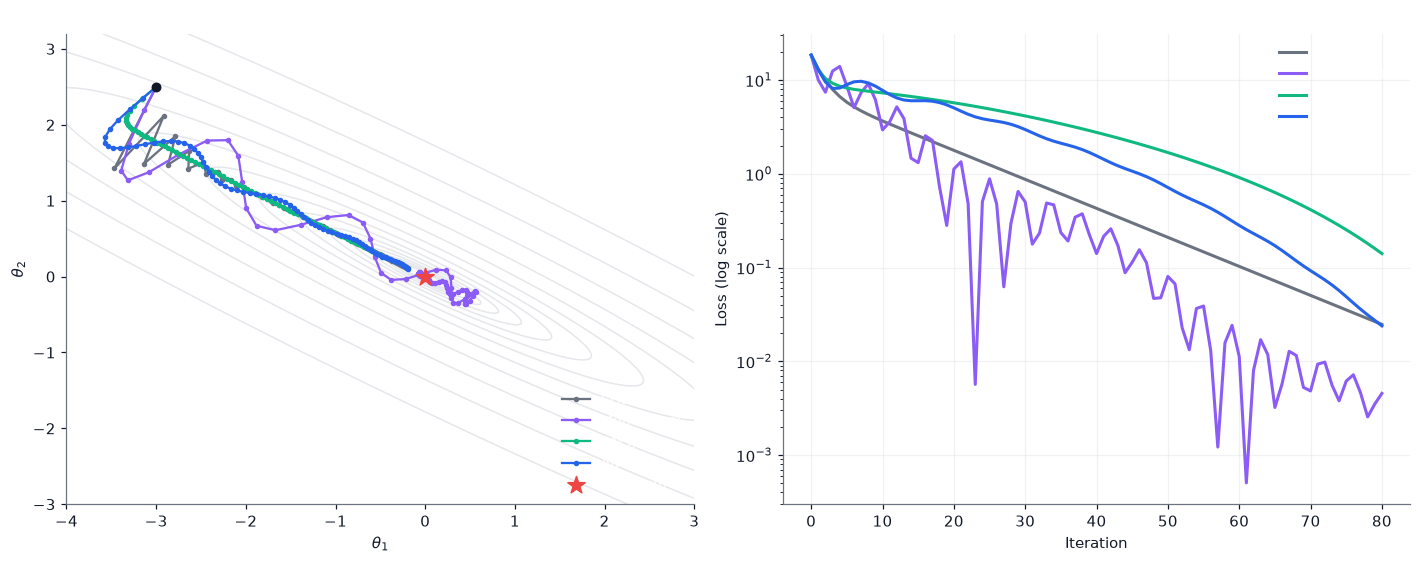

In [8]:
angle = np.deg2rad(30)
R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
A_toy = R.T @ np.diag([1.0, 50.0]) @ R
f_toy = lambda th: 0.5 * th @ A_toy @ th
grad_toy = lambda th: A_toy @ th

def optimize_toy(step_fn, theta0, n_steps=80, **kw):
    theta, state = np.array(theta0, dtype=float), {}
    path, losses = [theta.copy()], [f_toy(theta)]
    for _ in range(n_steps):
        theta, state = step_fn(theta, grad_toy(theta), state, **kw)
        path.append(theta.copy()); losses.append(f_toy(theta))
    return np.array(path), np.array(losses)

theta0 = [-3.0, 2.5]
runs = {
    "SGD":      optimize_toy(sgd_step, theta0, lr=0.035),
    "Momentum": optimize_toy(momentum_step, theta0, lr=0.01, beta=0.9),
    "RMSprop":  optimize_toy(rmsprop_step, theta0, lr=0.05),
    "Adam":     optimize_toy(adam_step, theta0, lr=0.15),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
gx, gy = np.meshgrid(np.linspace(-4, 3, 300), np.linspace(-3, 3.2, 300))
gz = 0.5 * (A_toy[0, 0] * gx**2 + 2 * A_toy[0, 1] * gx * gy + A_toy[1, 1] * gy**2)
axes[0].contour(gx, gy, gz, levels=np.geomspace(0.05, 60, 14), colors=COLORS["light"], linewidths=1.0)
axes[0].grid(False)
for name, (path, _) in runs.items():
    axes[0].plot(path[:, 0], path[:, 1], "-o", markersize=2.6, linewidth=1.5, color=OPT_COLORS[name], label=name)
axes[0].scatter([0], [0], marker="*", s=140, color=COLORS["red"], zorder=5, label="Minimum")
axes[0].scatter([theta0[0]], [theta0[1]], color=COLORS["dark"], zorder=5, s=30)
axes[0].set_xlabel(r"$\theta_1$"); axes[0].set_ylabel(r"$\theta_2$"); axes[0].set_title("Trajectories on the loss surface (toy, hand-tuned rates)")
axes[0].legend(loc="lower right")
for name, (_, losses) in runs.items():
    axes[1].semilogy(losses + 1e-12, color=OPT_COLORS[name], label=name)
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Loss (log scale)"); axes[1].set_title("Loss against iteration"); axes[1].legend()
finish(fig, "04_optimizers_toy")

What the figure shows (deterministic, so you will see the same picture):

- **SGD** is limited by the steep direction ($\eta < 2/\lambda_{\max}$): it zigzags across the valley at first and then descends steadily, but slowly along the valley floor.
- **Momentum** builds speed along the valley and reaches the lowest loss after 80 steps, but its loss is **not monotonic**: the velocity overshoots and the path spirals around the minimum.
- **RMSprop and Adam** move smoothly, yet in this example they are **not faster** than SGD or momentum. The reason is the geometry: the valley is rotated by 30°, so rescaling each *coordinate* separately cannot remove the ill-conditioning (a diagonal rescaling helps when the badly scaled directions are aligned with the axes). With a constant step they would also keep oscillating at a distance of the order of $\eta$ from the minimum; a **learning-rate schedule** removes this.

None of this proves that one method is "best": it depends on the problem, the noise, and the tuning. Adaptive methods are popular for deep networks because their per-parameter scaling is very useful when different layers and features have very different gradient magnitudes, a situation that this two-parameter toy does not have.

## 7. Regularization: the mathematics

A regularized objective adds a penalty $\Omega(\theta)$ to the data-fit term:

$$
L_{\text{reg}}(\theta) = \hat{R}(\theta) + \lambda\,\Omega(\theta) .
$$

The **Bayesian (MAP) view**: minimizing the negative log-posterior $-\ln p(\mathcal{D}\mid\theta) - \ln p(\theta)$ gives a penalty equal to the negative log-prior. A Gaussian prior produces an L2 penalty, a Laplace prior an L1 penalty.

### 7.1 L2 regularization (weight decay, ridge)

$$
\Omega_2(w) = \tfrac{1}{2}\lVert w\rVert_2^2, \qquad \nabla L_{\text{reg}} = \nabla \hat{R} + \lambda w .
$$

A gradient step becomes

$$
w \leftarrow w - \eta(\nabla\hat{R} + \lambda w) = (1 - \eta\lambda)\,w - \eta\nabla\hat{R},
$$

so every step first **shrinks the weights by the factor $1 - \eta\lambda$** (hence the name *weight decay*). A Gaussian prior $w_j \sim \mathcal{N}(0, 1/\lambda)$ gives the same penalty.

**Keras convention:** `keras.regularizers.L2(l2)` adds $\text{l2}\sum_j w_j^2$ to the loss, i.e. $\lambda_{\text{here}} = 2\cdot\text{l2}$.

**Ridge regression.** For least squares $\min_w \lVert Zw - y\rVert^2 + \lambda\lVert w\rVert^2$, the solution is $w_\lambda = (Z^{\top}Z + \lambda I)^{-1}Z^{\top}y$. With the singular value decomposition $Z = U S V^{\top}$ (singular values $s_i$), the fitted values become

$$
Z w_\lambda = \sum_i u_i\,\frac{s_i^{2}}{s_i^{2}+\lambda}\,u_i^{\top}y .
$$

Each component is shrunk by the **filter factor $s_i^2/(s_i^2 + \lambda)$**: directions with large singular values (well-determined by the data) are almost untouched, while directions with small singular values — exactly the **collinear directions** that caused trouble in Notebook 05 — are shrunk strongly. Ridge is the remedy for collinearity.

Correlation between the two features: 0.9997


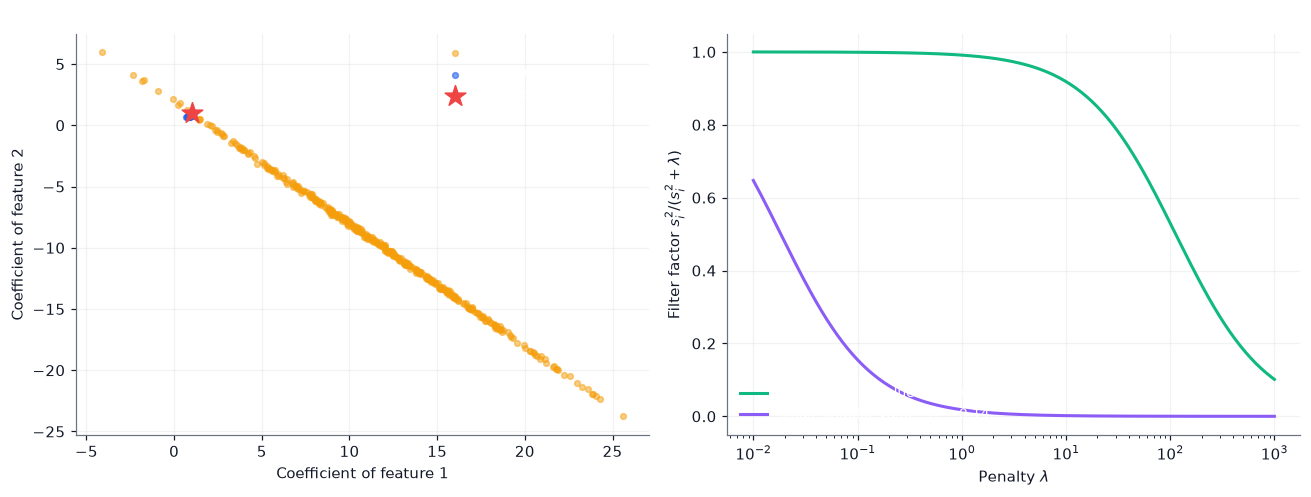

Standard deviation of the coefficient estimates (OLS):  [5.32 5.32]
Standard deviation of the coefficient estimates (ridge): [0.06 0.07]


In [9]:
# Collinearity: two almost identical features. Compare OLS and ridge across bootstrap resamples.
rg = np.random.default_rng(5)
n_c = 60
z1 = rg.normal(size=n_c)
z2 = z1 + rg.normal(0, 0.03, size=n_c)                  # correlation about 0.999
Z_c = np.column_stack([z1, z2])
y_c = z1 + z2 + rg.normal(0, 1.0, size=n_c)             # the true coefficients are (1, 1)
print("Correlation between the two features:", round(float(np.corrcoef(z1, z2)[0, 1]), 4))

def ridge_fit(Z, y, lam):
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

ols_coefs, ridge_coefs = [], []
for _ in range(400):
    idx = rg.integers(0, n_c, size=n_c)
    ols_coefs.append(ridge_fit(Z_c[idx], y_c[idx], 0.0))
    ridge_coefs.append(ridge_fit(Z_c[idx], y_c[idx], 5.0))
ols_coefs, ridge_coefs = np.array(ols_coefs), np.array(ridge_coefs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(ols_coefs[:, 0], ols_coefs[:, 1], s=14, alpha=0.5, color=COLORS["orange"], label="OLS (no penalty)")
axes[0].scatter(ridge_coefs[:, 0], ridge_coefs[:, 1], s=14, alpha=0.6, color=COLORS["blue"], label=r"Ridge ($\lambda = 5$)")
axes[0].scatter([1], [1], marker="*", s=200, color=COLORS["red"], zorder=5, label="True coefficients (1, 1)")
axes[0].set_xlabel("Coefficient of feature 1"); axes[0].set_ylabel("Coefficient of feature 2")
axes[0].set_title("Bootstrap coefficients with two collinear features"); axes[0].legend(loc="upper right")

# Filter factors for the two singular directions of this design matrix.
s_vals = np.linalg.svd(Z_c, compute_uv=False)
lam_grid = np.geomspace(1e-2, 1e3, 200)
for s_i, color, label in zip(s_vals, [COLORS["green"], COLORS["purple"]],
                             [f"large singular value  $s_1$ = {s_vals[0]:.1f}", f"small singular value  $s_2$ = {s_vals[1]:.2f}"]):
    axes[1].semilogx(lam_grid, s_i**2 / (s_i**2 + lam_grid), color=color, label=label)
axes[1].set_xlabel(r"Penalty $\lambda$"); axes[1].set_ylabel(r"Filter factor $s_i^2/(s_i^2+\lambda)$")
axes[1].set_title("Ridge shrinks weakly determined directions first"); axes[1].legend(loc="lower left")
finish(fig, "05_ridge_collinearity")
print("Standard deviation of the coefficient estimates (OLS): ", np.round(ols_coefs.std(axis=0), 2))
print("Standard deviation of the coefficient estimates (ridge):", np.round(ridge_coefs.std(axis=0), 2))

The OLS estimates scatter widely along the anti-diagonal: only the *sum* of the two coefficients is determined by the data, not each one separately. Ridge pulls the estimates towards a stable compromise and greatly reduces the variance, at the price of a small bias.

### 7.2 L1 regularization (lasso, sparsity)

$$
\Omega_1(w) = \lVert w\rVert_1 = \sum_j |w_j|, \qquad \partial\,\lambda|w_j| = \lambda\operatorname{sign}(w_j)\quad (w_j \neq 0).
$$

A Laplace prior gives this penalty. To see what it does, consider the simplest case $\min_w \tfrac{1}{2}(w - z)^2 + \lambda\Omega(w)$, where $z$ is the unpenalized solution:

$$
\text{L2: } w^{*} = \frac{z}{1+\lambda}, \qquad\qquad
\text{L1: } w^{*} = \operatorname{sign}(z)\,\max(|z| - \lambda,\, 0) \quad\text{(soft-thresholding)} .
$$

L2 **shrinks proportionally** and never produces an exact zero. L1 **subtracts a constant and truncates at zero**: every coefficient with $|z| \le \lambda$ becomes **exactly zero**, which gives sparse solutions. In a network, L1 on the weights pushes many of them to zero (useful for feature selection from thousands of genes), but its effect on accuracy is often smaller than that of L2 or Dropout.

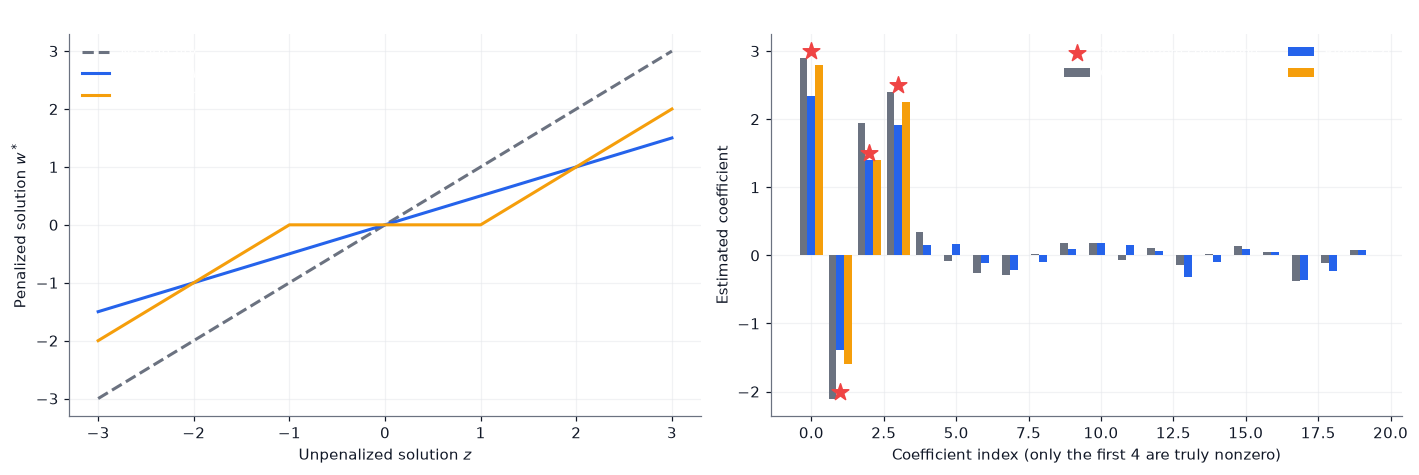

Exact zeros among the 16 irrelevant coefficients -> OLS: 0 | ridge: 0 | lasso: 16


In [10]:
z_grid = np.linspace(-3, 3, 601)
lam_demo = 1.0
l2_solution = z_grid / (1 + lam_demo)
l1_solution = np.sign(z_grid) * np.maximum(np.abs(z_grid) - lam_demo, 0.0)

# A sparse regression problem solved with ISTA (proximal gradient) for the lasso, closed form for ridge.
rs = np.random.default_rng(11)
n_s, p_s, k_true = 60, 20, 4
Z_s = rs.normal(size=(n_s, p_s))
w_true = np.zeros(p_s); w_true[:k_true] = [3.0, -2.0, 1.5, 2.5]
y_s = Z_s @ w_true + rs.normal(0, 1.0, size=n_s)

def lasso_ista(Z, y, lam, iters=5000):
    n = len(Z); step = 1.0 / (np.linalg.norm(Z, 2) ** 2 / n)
    w = np.zeros(Z.shape[1])
    for _ in range(iters):
        w = w - step * (Z.T @ (Z @ w - y) / n)
        w = np.sign(w) * np.maximum(np.abs(w) - step * lam, 0.0)         # soft-thresholding
    return w

w_ols_s = np.linalg.lstsq(Z_s, y_s, rcond=None)[0]
w_ridge_s = ridge_fit(Z_s, y_s, 20.0)
w_lasso_s = lasso_ista(Z_s, y_s, lam=0.35)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(z_grid, z_grid, color=COLORS["gray"], linestyle="--", label="No penalty")
axes[0].plot(z_grid, l2_solution, color=COLORS["blue"], label=r"L2: $z/(1+\lambda)$")
axes[0].plot(z_grid, l1_solution, color=COLORS["orange"], label="L1: soft-thresholding")
axes[0].set_xlabel("Unpenalized solution $z$"); axes[0].set_ylabel("Penalized solution $w^*$")
axes[0].set_title(r"Shrinkage rules ($\lambda=1$)"); axes[0].legend(loc="upper left")

x = np.arange(p_s); width = 0.27
axes[1].bar(x - width, w_ols_s, width, color=COLORS["gray"], label="OLS")
axes[1].bar(x, w_ridge_s, width, color=COLORS["blue"], label="Ridge (L2)")
axes[1].bar(x + width, w_lasso_s, width, color=COLORS["orange"], label="Lasso (L1)")
axes[1].scatter(x[:k_true], w_true[:k_true], marker="*", s=130, color=COLORS["red"], zorder=5, label="True nonzero coefficients")
axes[1].set_xlabel("Coefficient index (only the first 4 are truly nonzero)"); axes[1].set_ylabel("Estimated coefficient")
axes[1].set_title("Sparse problem: 20 features, 4 relevant, 60 samples"); axes[1].legend(ncol=2, fontsize=8.5)
finish(fig, "06_l1_vs_l2")
print("Exact zeros among the 16 irrelevant coefficients -> OLS:", int(np.sum(w_ols_s[k_true:] == 0)),
      "| ridge:", int(np.sum(w_ridge_s[k_true:] == 0)), "| lasso:", int(np.sum(w_lasso_s[k_true:] == 0)))

### 7.3 Dropout

During training, **inverted dropout** multiplies each activation $a_j$ by a random mask:

$$
\tilde{a}_j = \frac{m_j}{1-p}\,a_j, \qquad m_j \sim \operatorname{Bernoulli}(1-p),
$$

where $p$ is the dropout rate (Keras: `Dropout(p)`). Because $\mathbb{E}[m_j] = 1-p$, we have $\mathbb{E}[\tilde{a}_j] = a_j$: the factor $1/(1-p)$ keeps the **expected activation unchanged**, so at inference time dropout is simply switched off with no rescaling.

Each training step trains a different random "thinned" sub-network; the full network at inference approximates an average over exponentially many of them (a cheap ensemble). Neurons cannot rely on specific partners being present, which discourages co-adaptation.

**Dropout as an adaptive L2 penalty.** For a linear model $\hat{y} = \sum_j w_j z_j \tilde{m}_j$ with $\tilde{m}_j = m_j/(1-p)$ (mean 1, variance $p/(1-p)$), the expected squared error over the masks is

$$
\mathbb{E}_m\big[(y - \hat{y})^2\big]
= \Big(y - \sum_j w_j z_j\Big)^2 + \frac{p}{1-p}\sum_j w_j^2 z_j^2 .
$$

(*Proof:* $\hat{y}$ has mean $\sum_j w_j z_j$ and variance $\sum_j w_j^2 z_j^2 \operatorname{Var}(\tilde{m}_j)$; add squared bias and variance.) Averaged over the data, the second term is an **L2 penalty whose weight for coefficient $j$ is proportional to the feature's second moment** $\mathbb{E}[z_j^2]$: a ridge penalty adapted to the scale of each input. We verify the formula by simulation.

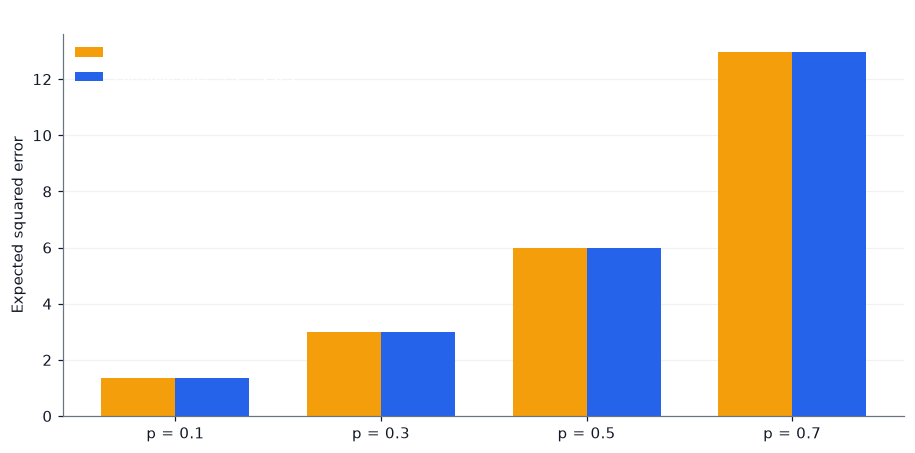

Relative differences: [0.0002 0.0001 0.0003 0.0006]


In [11]:
rs = np.random.default_rng(2)
z_one = rs.normal(size=6)
w_one = rs.normal(size=6)
y_one = 1.3

fig, ax = plt.subplots(figsize=(8.4, 4.2))
rates = [0.1, 0.3, 0.5, 0.7]
mc_values, formula_values = [], []
for p_drop in rates:
    masks = (rs.random(size=(400_000, 6)) > p_drop) / (1 - p_drop)               # inverted dropout masks
    y_hat = (masks * (w_one * z_one)).sum(axis=1)
    mc_values.append(np.mean((y_one - y_hat) ** 2))
    formula_values.append((y_one - w_one @ z_one) ** 2 + p_drop / (1 - p_drop) * np.sum(w_one**2 * z_one**2))
    assert abs(np.mean(masks) - 1.0) < 0.01                                      # E[m/(1-p)] = 1
x = np.arange(len(rates)); width = 0.36
ax.bar(x - width / 2, mc_values, width, color=COLORS["orange"], label="Monte-Carlo (400,000 random masks)")
ax.bar(x + width / 2, formula_values, width, color=COLORS["blue"], label=r"Formula: bias$^2$ + $\frac{p}{1-p}\sum w_j^2 z_j^2$")
ax.set_xticks(x); ax.set_xticklabels([f"p = {p}" for p in rates]); ax.set_ylabel("Expected squared error")
ax.set_title("Dropout acts as an input-dependent L2 penalty"); ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
finish(fig, "07_dropout_formula")
print("Relative differences:", np.round(np.abs(np.array(mc_values) / np.array(formula_values) - 1), 4))

### 7.4 Batch normalization

For a mini-batch of activations $x_1, \dots, x_B$ of one unit, a batch normalization layer computes

$$
\mu_B = \frac{1}{B}\sum_i x_i, \qquad
\sigma_B^{2} = \frac{1}{B}\sum_i (x_i - \mu_B)^2, \qquad
\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^{2} + \varepsilon}}, \qquad
y_i = \gamma\,\hat{x}_i + \beta,
$$

with learnable scale $\gamma$ and shift $\beta$. Three practical points:

1. **Training versus inference.** During training the batch statistics $\mu_B, \sigma_B^2$ are used, and running averages are updated, $\mu \leftarrow m\,\mu + (1-m)\,\mu_B$ (Keras: momentum $m = 0.99$). At inference the **running averages** are used, so a single sample can be processed.
2. **Mild regularization.** Batch statistics are noisy (they depend on which samples share the batch), which injects noise much like Dropout.
3. **Why it helps optimization.** The original motivation was to reduce "internal covariate shift"; later work suggests that it mainly makes the loss landscape smoother, allowing larger learning rates. The explanation is still debated; the empirical effect is not.

With batch normalization the bias of the preceding Dense layer is redundant ($\beta$ takes over), so we use `use_bias=False` there.

In [12]:
rs = np.random.default_rng(4)
batch_demo = rs.normal(3.0, 2.5, size=(64, 5)).astype("float32")

def batch_norm_numpy(x, gamma=1.0, beta=0.0, eps=1e-3):
    mu, var = x.mean(axis=0), x.var(axis=0)                       # biased variance, as in the formula
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

ours = batch_norm_numpy(batch_demo)
layer = keras.layers.BatchNormalization(epsilon=1e-3)
theirs = keras.ops.convert_to_numpy(layer(batch_demo, training=True))
print("Batch normalization: max difference between our formula and Keras (training mode):", f"{np.max(np.abs(ours - theirs)):.2e}")
print("Per-feature mean after normalization:", np.round(ours.mean(axis=0), 4))
print("Per-feature std  after normalization:", np.round(ours.std(axis=0), 3))

# Inference mode uses the running averages, which have barely moved after one batch (momentum 0.99):
inference_out = keras.ops.convert_to_numpy(layer(batch_demo, training=False))
print("Inference-mode output differs from training-mode output by up to", f"{np.max(np.abs(inference_out - theirs)):.2f}",
      "after a single update of the running statistics.")

Batch normalization: max difference between our formula and Keras (training mode): 4.77e-07
Per-feature mean after normalization: [ 0.  0. -0. -0. -0.]
Per-feature std  after normalization: [1. 1. 1. 1. 1.]
Inference-mode output differs from training-mode output by up to 6.98 after a single update of the running statistics.


### 7.5 Early stopping as implicit regularization

Gradient descent started from $w_0 = 0$ on a quadratic loss with Hessian eigenvalues $\lambda_i$ reaches, after $t$ steps, in the eigendirection $i$:

$$
w_i(t) = \big[\,1 - (1-\eta\lambda_i)^{t}\,\big]\,w_i^{*},
$$

where $w^{*}$ is the unregularized minimizer. Compare this with the ridge solution, $w_i^{\text{ridge}} = \dfrac{\lambda_i}{\lambda_i+\alpha}\,w_i^{*}$. For small $\eta\lambda_i$,

$$
1-(1-\eta\lambda_i)^t \approx 1 - e^{-\eta\lambda_i t},
$$

which, like the ridge factor, is close to 1 for large $\lambda_i$ and close to 0 for small $\lambda_i$, with the transition near $\lambda_i \approx 1/(\eta t)$. Hence **stopping after $t$ steps behaves roughly like ridge regularization with $\alpha \approx 1/(\eta t)$**: early stopping restricts how far the weights can move from their initial values in the poorly determined directions. Training for longer means weaker regularization.

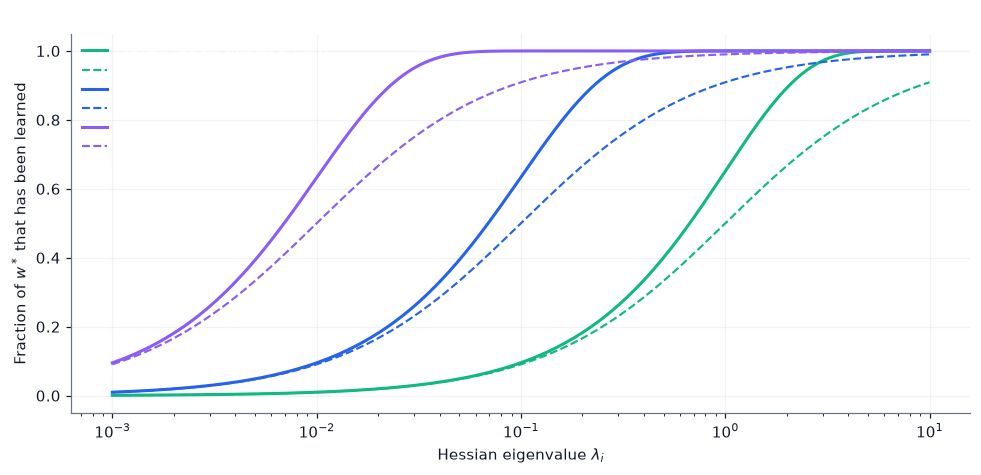

In [13]:
eigs = np.geomspace(1e-3, 1e1, 300)
eta_es = 0.1
fig, ax = plt.subplots(figsize=(9, 4.4))
for t_steps, color in [(10, COLORS["green"]), (100, COLORS["blue"]), (1000, COLORS["purple"])]:
    ax.semilogx(eigs, 1 - (1 - eta_es * eigs) ** t_steps, color=color, label=f"Gradient descent stopped at t = {t_steps}")
    alpha_equiv = 1.0 / (eta_es * t_steps)
    ax.semilogx(eigs, eigs / (eigs + alpha_equiv), color=color, linestyle="--", linewidth=1.4,
                label=rf"Ridge with $\alpha = 1/(\eta t)$ = {alpha_equiv:.3g}")
ax.set_xlabel(r"Hessian eigenvalue $\lambda_i$"); ax.set_ylabel("Fraction of $w^*$ that has been learned")
ax.set_title("Early stopping and ridge shrink the same (small-eigenvalue) directions"); ax.legend(fontsize=8, loc="upper left")
finish(fig, "08_early_stopping_vs_ridge")

# Part II — Experimental infrastructure

## 8. Reusable tools for controlled experiments

We now study these techniques on real data. To make comparisons **fair and informative**:

- every configuration is trained with **several seeds** and reported as mean ± standard deviation (a single run cannot separate an effect from random initialization);
- performance is measured in **inference mode** after every epoch on the training and the validation set, with the same function for every technique (Keras' reported training loss would otherwise include dropout noise and regularization penalties and could not be compared);
- the test set is **not touched** until the final evaluation of each dataset.

### 8.1 Metrics (as in Notebook 04)

In [14]:
def confusion_matrix_np(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def summary_metrics(cm):
    """Accuracy, macro-F1 (over classes present in the true labels), and multiclass MCC."""
    cm = np.asarray(cm, dtype=float)
    tp, predicted, support = np.diag(cm), cm.sum(axis=0), cm.sum(axis=1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    present = support > 0
    total = cm.sum()
    denominator = np.sqrt((total**2 - np.sum(predicted**2)) * (total**2 - np.sum(support**2)))
    mcc = (np.trace(cm) * total - np.sum(predicted * support)) / denominator if denominator > 0 else 0.0
    return {"accuracy": float(np.trace(cm) / total), "macro_f1": float(f1[present].mean()), "mcc": float(mcc)}

def cross_entropy_np(y_int, probs, eps=1e-7):
    p = np.clip(probs[np.arange(len(y_int)), y_int], eps, 1.0)
    return float(-np.mean(np.log(p)))

def stratified_split_indices(labels, val_fraction=0.15, test_fraction=0.15, seed=SEED):
    """Train/validation/test indices; every class appears in every partition."""
    split_rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for class_id in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == class_id))
        n_val = max(1, int(round(val_fraction * len(idx))))
        n_test = max(1, int(round(test_fraction * len(idx))))
        val_idx.append(idx[:n_val]); test_idx.append(idx[n_val:n_val + n_test]); train_idx.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(part)) for part in (train_idx, val_idx, test_idx)]

def make_data(X_all, y_all, train_idx, val_idx, test_idx, n_classes, class_names, select_top_k=None):
    """Bundle the partitions. If select_top_k is given, the k highest-variance features are chosen
    from the TRAINING partition only (no information from validation or test is used)."""
    cols = np.arange(X_all.shape[1])
    if select_top_k is not None:
        cols = np.argsort(-X_all[train_idx].var(axis=0))[:select_top_k]
    data = {"columns": cols, "n_classes": n_classes, "class_names": class_names}
    for part, idx in (("train", train_idx), ("val", val_idx), ("test", test_idx)):
        data[f"X_{part}"] = np.ascontiguousarray(X_all[idx][:, cols], dtype="float32")
        data[f"y_{part}"] = y_all[idx].astype("int32")
        data[f"Y_{part}"] = keras.utils.to_categorical(y_all[idx], num_classes=n_classes).astype("float32")
    return data

### 8.2 A configurable network and an evaluation callback

The builder creates the same family of networks for both datasets; Dropout, L1/L2 penalties, and batch normalization can be switched on independently. The `Normalization` layer is adapted on the **training features only**.

In [15]:
def build_classifier(X_adapt, n_classes, hidden_units=(128, 128), dropout=0.0, l1=0.0, l2=0.0,
                     batch_norm=False, name="mlp"):
    """MLP classifier with optional Dropout, L1/L2 weight penalties, and batch normalization."""
    normalization = keras.layers.Normalization(axis=-1, name="normalize_features")
    normalization.adapt(X_adapt)
    regularizer = keras.regularizers.L1L2(l1=l1, l2=l2) if (l1 > 0 or l2 > 0) else None
    layers = [keras.layers.Input(shape=(X_adapt.shape[1],), name="features"), normalization]
    for i, units in enumerate(hidden_units, start=1):
        layers.append(keras.layers.Dense(units, kernel_regularizer=regularizer, use_bias=not batch_norm, name=f"dense_{i}"))
        if batch_norm:
            layers.append(keras.layers.BatchNormalization(name=f"batch_norm_{i}"))
        layers.append(keras.layers.Activation("relu", name=f"relu_{i}"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    layers.append(keras.layers.Dense(n_classes, activation="softmax", name="class_probabilities"))
    return keras.Sequential(layers, name=name)

def count_trainable(model):
    return sum(int(np.prod(w.shape)) for w in model.trainable_weights)

class EvalCallback(keras.callbacks.Callback):
    """After every epoch, evaluate in INFERENCE mode: train/validation cross-entropy (no penalties, no dropout),
    accuracies, and the validation macro-F1. Results are stored in lists for later analysis."""
    def __init__(self, data):
        super().__init__()
        self.d = data
    def on_train_begin(self, logs=None):
        self.train_loss, self.val_loss, self.train_acc, self.val_acc, self.val_f1 = [], [], [], [], []
    def on_epoch_end(self, epoch, logs=None):
        p_train = keras.ops.convert_to_numpy(self.model(self.d["X_train"], training=False))
        p_val = keras.ops.convert_to_numpy(self.model(self.d["X_val"], training=False))
        self.train_loss.append(cross_entropy_np(self.d["y_train"], p_train))
        self.val_loss.append(cross_entropy_np(self.d["y_val"], p_val))
        self.train_acc.append(float(np.mean(p_train.argmax(1) == self.d["y_train"])))
        self.val_acc.append(float(np.mean(p_val.argmax(1) == self.d["y_val"])))
        cm = confusion_matrix_np(self.d["y_val"], p_val.argmax(1), self.d["n_classes"])
        self.val_f1.append(summary_metrics(cm)["macro_f1"])

def make_optimizer(kind, learning_rate):
    if kind == "SGD":
        return keras.optimizers.SGD(learning_rate=learning_rate)
    if kind == "Momentum":
        return keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    if kind == "RMSprop":
        return keras.optimizers.RMSprop(learning_rate=learning_rate)
    if kind == "Adam":
        return keras.optimizers.Adam(learning_rate=learning_rate)
    raise ValueError(kind)

def run_experiment(data, config, seed, epochs, optimizer="Adam", learning_rate=1e-3, batch_size=32, name="mlp"):
    """Train one network for a fixed number of epochs (no early stopping) and return its per-epoch curves."""
    keras.utils.set_random_seed(seed)
    model = build_classifier(data["X_train"], data["n_classes"], name=name, **config)
    model.compile(optimizer=make_optimizer(optimizer, learning_rate), loss="categorical_crossentropy")
    recorder = EvalCallback(data)
    model.fit(data["X_train"], data["Y_train"], epochs=epochs, batch_size=batch_size, callbacks=[recorder], verbose=0)
    return {"train_loss": np.array(recorder.train_loss), "val_loss": np.array(recorder.val_loss),
            "train_acc": np.array(recorder.train_acc), "val_acc": np.array(recorder.val_acc),
            "val_f1": np.array(recorder.val_f1), "n_params": count_trainable(model)}

def run_many(data, config, epochs, seeds=None, **kwargs):
    """Repeat run_experiment over seeds and stack the curves: arrays of shape (n_seeds, epochs)."""
    seeds = list(range(SEED, SEED + N_SEEDS)) if seeds is None else seeds
    runs = [run_experiment(data, config, s, epochs, **kwargs) for s in seeds]
    out = {k: np.stack([r[k] for r in runs]) for k in ("train_loss", "val_loss", "train_acc", "val_acc", "val_f1")}
    out["n_params"] = runs[0]["n_params"]
    return out

def summarize(results):
    """One row per configuration. 'Best epoch' = epoch of the minimum validation loss, i.e. what early stopping would pick."""
    rows = {}
    for name, r in results.items():
        best = r["val_loss"].argmin(axis=1)                              # per seed
        idx = np.arange(len(best))
        rows[name] = {
            "parameters": r["n_params"],
            "best epoch": f"{best.mean() + 1:.0f}",
            "min val loss": f"{r['val_loss'][idx, best].mean():.3f} \u00b1 {r['val_loss'][idx, best].std():.3f}",
            "val macro-F1 @ best": f"{r['val_f1'][idx, best].mean():.3f} \u00b1 {r['val_f1'][idx, best].std():.3f}",
            "val acc @ best": f"{r['val_acc'][idx, best].mean():.3f}",
            "final val loss": f"{r['val_loss'][:, -1].mean():.3f} \u00b1 {r['val_loss'][:, -1].std():.3f}",
            "final train loss": f"{r['train_loss'][:, -1].mean():.3f}",
            "final gap (val \u2212 train)": f"{(r['val_loss'][:, -1] - r['train_loss'][:, -1]).mean():.3f}",
        }
    return pd.DataFrame(rows).T

def min_val_loss_mean(results, name):
    r = results[name]
    return float(r["val_loss"][np.arange(len(r["val_loss"])), r["val_loss"].argmin(axis=1)].mean())

### 8.3 Plotting helpers

Curves are drawn as the **mean over seeds** with a band of ±1 standard deviation. A dashed line marks the epoch of minimum mean validation loss — the epoch early stopping would choose.

In [16]:
def band(ax, curves, color, label, linestyle="-"):
    mean, sd = curves.mean(axis=0), curves.std(axis=0)
    x = np.arange(1, curves.shape[1] + 1)
    ax.plot(x, mean, color=color, label=label, linestyle=linestyle)
    ax.fill_between(x, mean - sd, mean + sd, color=color, alpha=0.15, linewidth=0)

def plot_curve_grid(results, names, title, fig_name, ncols=3, ylim=None):
    """Small multiples: training and validation cross-entropy for each configuration."""
    nrows = int(math.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.5 * nrows), sharey=True, squeeze=False)
    for ax, name in zip(axes.ravel(), names):
        r = results[name]
        band(ax, r["train_loss"], COLORS["blue"], "Training")
        band(ax, r["val_loss"], COLORS["orange"], "Validation")
        best = int(r["val_loss"].mean(axis=0).argmin()) + 1
        ax.axvline(best, color=COLORS["gray"], linestyle="--", linewidth=1)
        ax.set_title(name, fontsize=10.5); ax.set_xlabel("Epoch")
        if ylim: ax.set_ylim(*ylim)
        ax.text(0.97, 0.95, f"best epoch {best}\nval loss {r['val_loss'].mean(axis=0).min():.3f}", transform=ax.transAxes,
                ha="right", va="top", fontsize=8.5, color=COLORS["dark"])
    for ax in axes.ravel()[len(names):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("Cross-entropy")
    axes[0, 0].legend(loc="lower left")
    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.01)
    finish(fig, fig_name)

def plot_overlay(results, names, colors, title, fig_name, metric="val_loss", ylabel="Validation cross-entropy", ylim=None):
    fig, ax = plt.subplots(figsize=(9.6, 4.6))
    for name, color in zip(names, colors):
        band(ax, results[name][metric], color, name)
    if ylim: ax.set_ylim(*ylim)
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(loc="best", fontsize=8.5)
    finish(fig, fig_name)

# Part III — Dataset 1: Yeast protein localization

## 9. Data

We reload the dataset and split it exactly as in Notebook 04 (same seed, same stratified function), so the numbers are comparable. The dataset and its biology are described in Notebook 04.

- 1,484 proteins, 8 features, 10 localization classes; the smallest class has only 5 proteins.
- Training / validation / test: about 1,038 / 223 / 223 proteins.

In [17]:
CLASS_ORDER = ["CYT", "NUC", "MIT", "ME3", "ME2", "ME1", "EXC", "VAC", "POX", "ERL"]
YEAST_FEATURES = ["mcg", "gvh", "alm", "mit", "erl", "pox", "vac", "nuc"]
YEAST_COLUMNS = ["sequence_name"] + YEAST_FEATURES + ["localization_site"]
YEAST_PATH = os.path.join("data", "yeast.data")
YEAST_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/yeast/yeast.data"

def load_yeast(path=YEAST_PATH, url=YEAST_URL):
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print("Downloading:", url)
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as error:
            raise RuntimeError(f"Could not download the dataset ({error}). Download 'yeast.data' manually from "
                               f"https://archive.ics.uci.edu/dataset/110/yeast and save it as '{path}'.") from error
    return pd.read_csv(path, sep=r"\s+", header=None, names=YEAST_COLUMNS)

yeast_df = load_yeast()
assert yeast_df.shape == (1484, 10) and set(yeast_df["localization_site"]) == set(CLASS_ORDER)

X_yeast = yeast_df[YEAST_FEATURES].to_numpy(dtype="float32")
y_yeast = yeast_df["localization_site"].map({c: i for i, c in enumerate(CLASS_ORDER)}).to_numpy(dtype="int32")

yeast_split = stratified_split_indices(y_yeast)
data_yeast = make_data(X_yeast, y_yeast, *yeast_split, n_classes=len(CLASS_ORDER), class_names=CLASS_ORDER)

print("Training / validation / test:", len(data_yeast["y_train"]), "/", len(data_yeast["y_val"]), "/", len(data_yeast["y_test"]))
print("Iterations per epoch with batch size 32:", math.ceil(len(data_yeast["y_train"]) / 32))

# The reference network of this section: deliberately large for 8 features and ~1,000 samples,
# so that overfitting is easy to observe.
BASE_YEAST = dict(hidden_units=(128, 128))
print("Trainable parameters of the reference network:", count_trainable(build_classifier(data_yeast["X_train"], 10, **BASE_YEAST)),
      "| training samples:", len(data_yeast["y_train"]))

Training / validation / test: 1040 / 222 / 222
Iterations per epoch with batch size 32: 33
Trainable parameters of the reference network: 18954 | training samples: 1040


## 10. Experiment Y1 — the learning rate

We train the reference network with Adam for several learning rates (all other settings fixed, no regularization, no early stopping). Each setting is repeated with several seeds.

What we expect from Section 5: a rate that is too small makes training slow; one that is too large makes it unstable or lands at a worse solution; between them, a broad region works well. Because Adam adapts the step per coordinate, its useful range is typically around $10^{-4}$ to $10^{-2}$.

In [18]:
lr_values = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
EPOCHS_LR = epochs_for(80)

results_lr = {}
t0 = time.time()
for lr in lr_values:
    results_lr[f"lr={lr:g}"] = run_many(data_yeast, BASE_YEAST, EPOCHS_LR, optimizer="Adam", learning_rate=lr)
print(f"Done in {time.time() - t0:.0f} s")
display(summarize(results_lr)[["best epoch", "min val loss", "val macro-F1 @ best", "final val loss"]])

Done in 171 s


,best epoch,min val loss,val macro-F1 @ best,final val loss
lr=0.0001,71,1.082 ± 0.000,0.591 ± 0.002,1.083 ± 0.001
lr=0.0003,25,1.082 ± 0.001,0.592 ± 0.003,1.120 ± 0.004
lr=0.001,10,1.086 ± 0.013,0.601 ± 0.004,1.317 ± 0.028
lr=0.003,5,1.091 ± 0.009,0.585 ± 0.018,2.352 ± 0.030
lr=0.01,4,1.099 ± 0.016,0.541 ± 0.071,3.823 ± 0.030
lr=0.03,2,1.170 ± 0.013,0.402 ± 0.053,2.662 ± 0.260
lr=0.1,28,1.315 ± 0.042,0.258 ± 0.041,1.576 ± 0.085


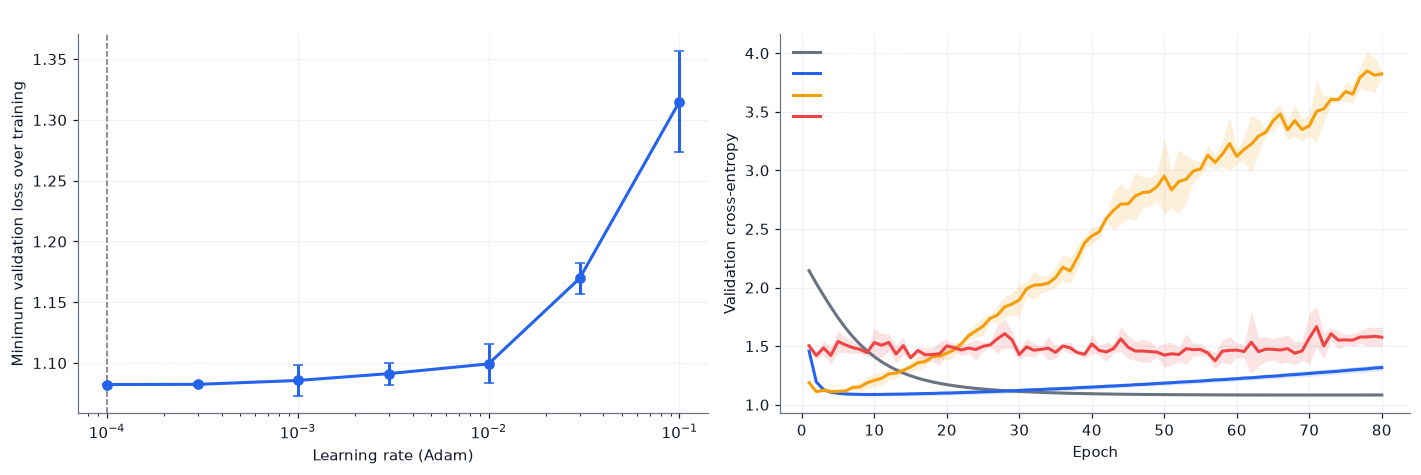

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
mins = np.array([[r["val_loss"][i].min() for i in range(N_SEEDS)] for r in results_lr.values()])
axes[0].errorbar(lr_values, mins.mean(axis=1), yerr=mins.std(axis=1), marker="o", color=COLORS["blue"], capsize=3)
best_lr = lr_values[int(mins.mean(axis=1).argmin())]
axes[0].axvline(best_lr, color=COLORS["gray"], linestyle="--", linewidth=1)
axes[0].annotate(f"best: {best_lr:g}", (best_lr, mins.mean(axis=1).min()), textcoords="offset points", xytext=(8, 12), fontsize=9)
axes[0].set_xscale("log"); axes[0].set_xlabel("Learning rate (Adam)"); axes[0].set_ylabel("Minimum validation loss over training")
axes[0].set_title("Best validation loss reached, by learning rate")

shown = ["lr=0.0001", "lr=0.001", "lr=0.01", "lr=0.1"]
for name, color in zip(shown, [COLORS["gray"], COLORS["blue"], COLORS["orange"], COLORS["red"]]):
    band(axes[1], results_lr[name]["val_loss"], color, name)
axes[1].set_ylim(top=min(6.0, axes[1].get_ylim()[1]))
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation cross-entropy"); axes[1].set_title("Validation loss curves"); axes[1].legend()
finish(fig, "09_yeast_learning_rate")

Read the right panel: a very small rate (grey) is still improving when training ends; the largest rate (red) is noisy and ends worse; the intermediate rates reach a low validation loss quickly and then **rise again** — that rise is overfitting, and it is the subject of Section 12. Note also that with a larger learning rate the minimum is reached in fewer epochs, so "the best rate" depends on the training budget.

## 11. Experiment Y2 — comparing optimizers fairly

The toy example of Section 6.4 compared optimizers with hand-chosen rates. On real data, a fair comparison **tunes the learning rate of each optimizer separately**; otherwise the result mostly reflects who happened to get a good rate. We try three rates per optimizer (on a grid suited to each method, because their natural scales differ) and keep the best by mean minimum validation loss.

In [20]:
optimizer_grid = {
    "SGD":      [3e-3, 3e-2, 3e-1],
    "Momentum": [1e-3, 1e-2, 1e-1],
    "RMSprop":  [1e-4, 1e-3, 1e-2],
    "Adam":     [1e-4, 1e-3, 1e-2],
}
EPOCHS_OPT = epochs_for(80)

grid_results = {}
t0 = time.time()
for opt_name, rates in optimizer_grid.items():
    for lr in rates:
        grid_results[(opt_name, lr)] = run_many(data_yeast, BASE_YEAST, EPOCHS_OPT, optimizer=opt_name, learning_rate=lr)
print(f"Done in {time.time() - t0:.0f} s")

def mean_min_val_loss(r):
    return float(np.mean([r["val_loss"][i].min() for i in range(len(r["val_loss"]))]))

best_per_opt = {}
rows = []
for opt_name, rates in optimizer_grid.items():
    scores = [mean_min_val_loss(grid_results[(opt_name, lr)]) for lr in rates]
    best_per_opt[opt_name] = rates[int(np.argmin(scores))]
    rows.append({"optimizer": opt_name, **{f"lr={lr:g}": f"{s:.3f}" for lr, s in zip(rates, scores)}, "best lr": best_per_opt[opt_name]})
display(pd.DataFrame(rows).set_index("optimizer"))

Done in 258 s


,lr=0.003,lr=0.03,lr=0.3,best lr,lr=0.001,lr=0.01,lr=0.1,lr=0.0001
optimizer,,,,,,,,
SGD,1.143,1.078,1.127,0.0300,NaN,NaN,NaN,NaN
Momentum,NaN,NaN,NaN,0.0010,1.077,1.081,1.106,NaN
RMSprop,NaN,NaN,NaN,0.0001,1.087,1.164,NaN,1.082
Adam,NaN,NaN,NaN,0.0001,1.086,1.099,NaN,1.082


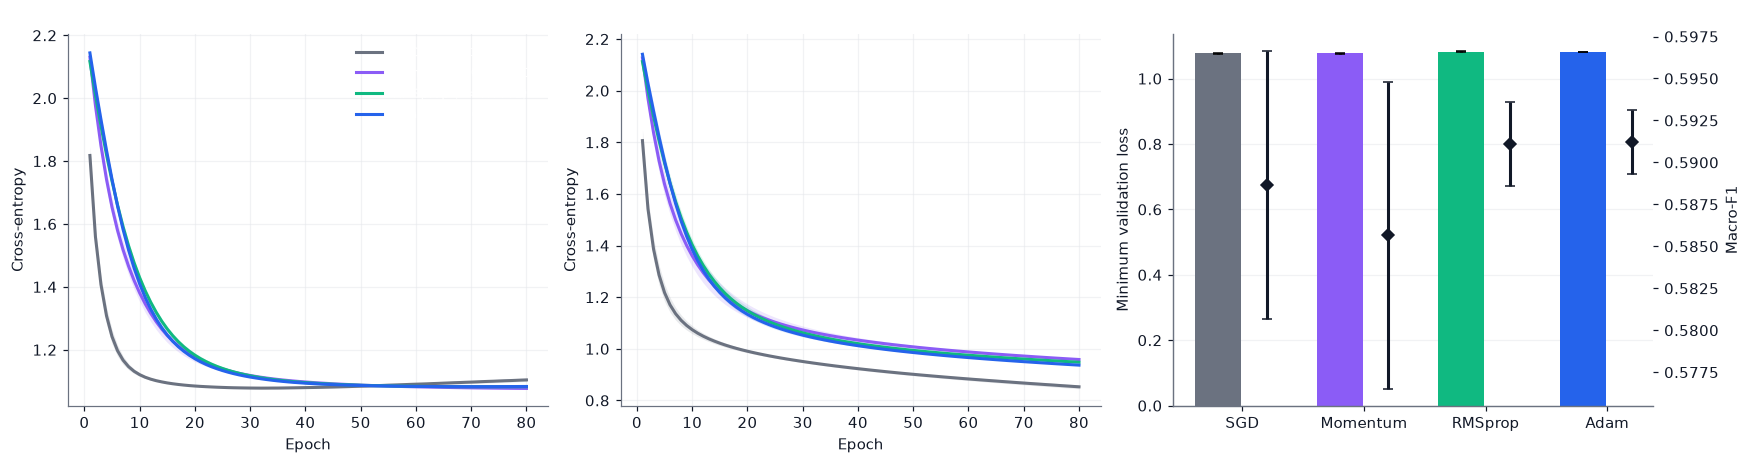

In [21]:
best_results = {name: grid_results[(name, lr)] for name, lr in best_per_opt.items()}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for name, r in best_results.items():
    band(axes[0], r["val_loss"], OPT_COLORS[name], f"{name} (lr={best_per_opt[name]:g})")
    band(axes[1], r["train_loss"], OPT_COLORS[name], name)
axes[0].set_title("Validation loss, best rate of each optimizer"); axes[1].set_title("Training loss (inference mode)")
for ax in axes[:2]:
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy")
axes[0].legend(fontsize=8.5)
names_o = list(best_results)
vals = [[best_results[n]["val_loss"][i].min() for i in range(N_SEEDS)] for n in names_o]
f1s = [[best_results[n]["val_f1"][i][best_results[n]["val_loss"][i].argmin()] for i in range(N_SEEDS)] for n in names_o]
x = np.arange(len(names_o))
axes[2].bar(x - 0.2, [np.mean(v) for v in vals], 0.38, yerr=[np.std(v) for v in vals], color=[OPT_COLORS[n] for n in names_o], capsize=3, label="Min validation loss")
ax2 = axes[2].twinx(); ax2.grid(False)
ax2.errorbar(x + 0.2, [np.mean(v) for v in f1s], yerr=[np.std(v) for v in f1s], fmt="D", color=COLORS["dark"], capsize=3, label="Validation macro-F1 at that epoch")
axes[2].set_xticks(x); axes[2].set_xticklabels(names_o); axes[2].set_ylabel("Minimum validation loss"); ax2.set_ylabel("Macro-F1")
axes[2].set_title("Summary (mean \u00b1 SD over seeds)"); axes[2].grid(axis="x", visible=False)
finish(fig, "10_yeast_optimizers")

Interpretation guide:

- Once each optimizer has its own tuned rate, the **differences in the best validation loss are usually small** compared with the differences caused by a bad learning rate. Tuning the rate matters more than the choice of optimizer.
- The optimizers differ mainly in **how quickly** they reach the minimum (left panel) and in **how sensitive** they are to the rate (the table: SGD's good range is narrow, Adam's broad).
- That is why Adam with $\eta = 10^{-3}$ is such a common default: it works acceptably without tuning. It is not guaranteed to be the best.

## 12. Experiment Y3 — regularization ablation

We keep the (too large) reference network and **add one technique at a time**, then the combination. All runs: Adam, learning rate $10^{-3}$, batch size 32, a fixed number of epochs and **no early stopping**, so that overfitting is fully visible. Early stopping is evaluated afterwards from the same curves: it selects the epoch of minimum validation loss.

| Configuration | Setting |
|---|---|
| Baseline | none |
| L2 | `l2 = 1e-3` on all hidden kernels (Keras convention: penalty $= 10^{-3}\sum w^2$) |
| L1 | `l1 = 1e-4` |
| Dropout | rate 0.3 after each hidden layer |
| BatchNorm | batch normalization after each Dense layer |
| Dropout + L2 | both |

Done in 249 s


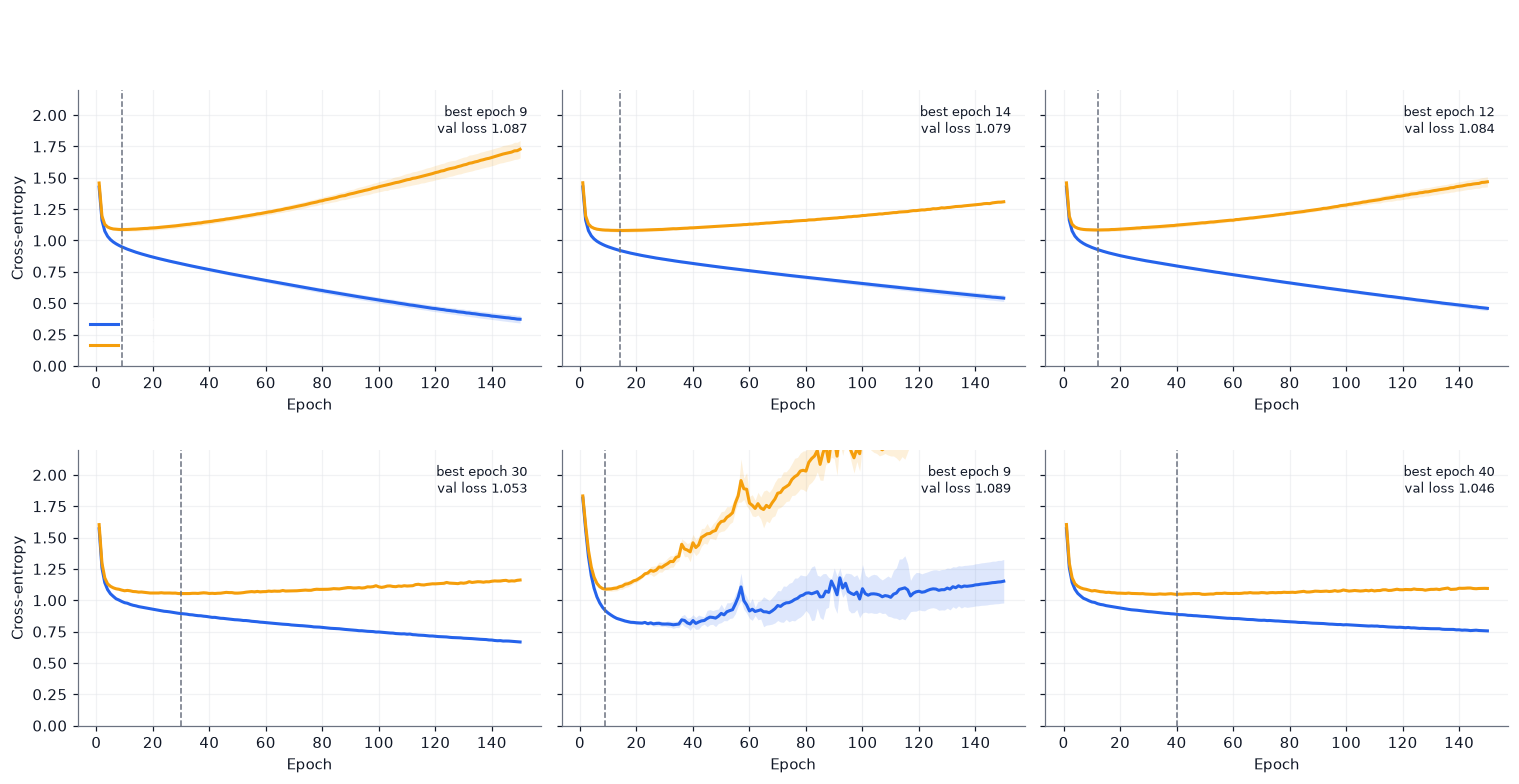

In [22]:
ablation_configs = {
    "Baseline":     dict(BASE_YEAST),
    "L2 (1e-3)":    dict(BASE_YEAST, l2=1e-3),
    "L1 (1e-4)":    dict(BASE_YEAST, l1=1e-4),
    "Dropout 0.3":  dict(BASE_YEAST, dropout=0.3),
    "BatchNorm":    dict(BASE_YEAST, batch_norm=True),
    "Dropout + L2": dict(BASE_YEAST, dropout=0.3, l2=1e-3),
}
EPOCHS_ABL = epochs_for(150)

results_yeast = {}
t0 = time.time()
for name, config in ablation_configs.items():
    results_yeast[name] = run_many(data_yeast, config, EPOCHS_ABL, optimizer="Adam", learning_rate=1e-3)
print(f"Done in {time.time() - t0:.0f} s")
plot_curve_grid(results_yeast, list(ablation_configs), "Yeast: training and validation loss for each configuration (mean \u00b1 SD over seeds)",
                "11_yeast_ablation_curves", ylim=(0, 2.2))

In [23]:
summary_yeast = summarize(results_yeast)
display(summary_yeast)

,parameters,best epoch,min val loss,val macro-F1 @ best,val acc @ best,final val loss,final train loss,final gap (val − train)
Baseline,18954,10,1.086 ± 0.013,0.601 ± 0.004,0.605,1.728 ± 0.070,0.372,1.356
L2 (1e-3),18954,15,1.078 ± 0.013,0.597 ± 0.004,0.599,1.309 ± 0.006,0.540,0.768
L1 (1e-4),18954,11,1.083 ± 0.013,0.600 ± 0.004,0.605,1.468 ± 0.040,0.459,1.009
Dropout 0.3,18954,37,1.047 ± 0.006,0.603 ± 0.003,0.610,1.162 ± 0.004,0.667,0.494
BatchNorm,19210,10,1.086 ± 0.016,0.578 ± 0.052,0.619,2.583 ± 0.102,1.152,1.431
Dropout + L2,18954,38,1.041 ± 0.004,0.605 ± 0.003,0.614,1.094 ± 0.010,0.756,0.339


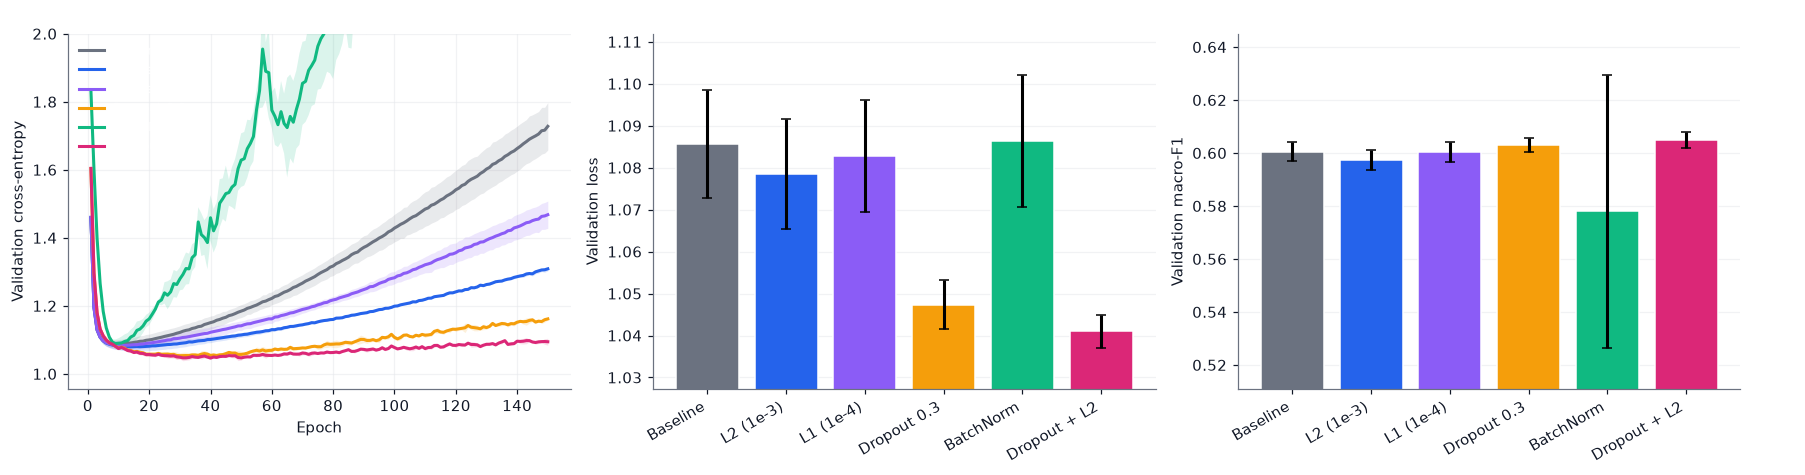

In [24]:
names_y = list(ablation_configs)
palette = [COLORS["gray"], COLORS["blue"], COLORS["purple"], COLORS["orange"], COLORS["green"], COLORS["pink"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for name, color in zip(names_y, palette):
    band(axes[0], results_yeast[name]["val_loss"], color, name)
axes[0].set_ylim(top=2.0); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Validation cross-entropy")
axes[0].set_title("Validation loss: when does overfitting start?"); axes[0].legend(fontsize=8)

def per_seed(results, name, key, at="best"):
    r = results[name]; idx = r["val_loss"].argmin(axis=1)
    return np.array([r[key][i][idx[i] if at == "best" else -1] for i in range(len(idx))])

for ax, (key, label, at) in zip(axes[1:], [("val_loss", "Validation loss", "best"), ("val_f1", "Validation macro-F1", "best")]):
    means = [per_seed(results_yeast, n, key, at).mean() for n in names_y]
    sds = [per_seed(results_yeast, n, key, at).std() for n in names_y]
    ax.bar(range(len(names_y)), means, yerr=sds, color=palette, capsize=3, edgecolor="white")
    ax.set_xticks(range(len(names_y))); ax.set_xticklabels(names_y, rotation=30, ha="right")
    ax.set_ylabel(label); ax.set_title(f"{label} at the best epoch (early stopping)"); ax.grid(axis="x", visible=False)
    lo, hi = min(m - s for m, s in zip(means, sds)), max(m + s for m, s in zip(means, sds))
    ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
finish(fig, "12_yeast_ablation_summary")

How to read the three figures (compare with your own numbers):

- **Baseline:** the validation loss reaches a minimum early and then climbs, while the training loss keeps falling: the network memorizes training proteins. The *final* validation loss is clearly worse than the minimum — **early stopping alone recovers most of the damage**, because it simply stops at the minimum.
- **L2, L1, Dropout, BatchNorm:** each one delays or flattens the rise of the validation loss. Look at the epoch of the minimum and at the *final gap* in the table, not only at the minimum value: regularization often matters more for **robustness to the training length** than for the best achievable value.
- **Differences in macro-F1** between configurations are usually within the seed-to-seed standard deviation on this dataset: rare classes with a handful of validation samples make F1 noisy. Do not over-interpret small differences; the validation *loss* is a smoother and more reliable criterion for model selection here.
- The best loss of a regularized model is usually only slightly better than that of the baseline stopped early. For a small tabular dataset with 8 features, the main benefit of regularization is **stability**, not a spectacular accuracy gain.

## 13. Selecting a configuration and evaluating on the test set

We apply a rule declared in advance: *among the six configurations, choose the one with the lowest mean minimum validation loss; then train it once more with early stopping (patience 20, restoring the best weights) and evaluate on the test set.* As a reference we do the same for the unregularized baseline with early stopping. Both models are fixed before the test set is used; the test results are **not** used to choose between them.

In [25]:
def train_final(data, config, seed=SEED, optimizer="Adam", learning_rate=1e-3, batch_size=32, max_epochs=300, patience=20, name="final"):
    """Train with early stopping on the validation loss and restore the best weights."""
    keras.utils.set_random_seed(seed)
    model = build_classifier(data["X_train"], data["n_classes"], name=name, **config)
    model.compile(optimizer=make_optimizer(optimizer, learning_rate), loss="categorical_crossentropy")
    stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    history = model.fit(data["X_train"], data["Y_train"], validation_data=(data["X_val"], data["Y_val"]),
                        epochs=max_epochs, batch_size=batch_size, callbacks=[stopper], verbose=0)
    return model, history

def bootstrap_classification(y_true, y_pred, n_classes, n_boot=2000, seed=0):
    resampler = np.random.default_rng(seed)
    n = len(y_true); acc, f1 = [], []
    for _ in range(n_boot):
        idx = resampler.integers(0, n, size=n)
        m = summary_metrics(confusion_matrix_np(y_true[idx], y_pred[idx], n_classes))
        acc.append(m["accuracy"]); f1.append(m["macro_f1"])
    return np.array(acc), np.array(f1)

def evaluate_on_test(data, model):
    probs = model.predict(data["X_test"], verbose=0)
    pred = probs.argmax(axis=1)
    cm = confusion_matrix_np(data["y_test"], pred, data["n_classes"])
    acc_boot, f1_boot = bootstrap_classification(data["y_test"], pred, data["n_classes"])
    return {"cm": cm, "pred": pred, "metrics": summary_metrics(cm), "test_loss": cross_entropy_np(data["y_test"], probs),
            "acc_ci": np.percentile(acc_boot, [2.5, 97.5]), "f1_ci": np.percentile(f1_boot, [2.5, 97.5])}

selected_yeast = min(results_yeast, key=lambda n: min_val_loss_mean(results_yeast, n))
print("Mean minimum validation loss:", {n: round(min_val_loss_mean(results_yeast, n), 3) for n in results_yeast})
print("Selected configuration:", selected_yeast)

model_sel_y, hist_sel_y = train_final(data_yeast, ablation_configs[selected_yeast], name="yeast_selected")
model_base_y, hist_base_y = train_final(data_yeast, ablation_configs["Baseline"], name="yeast_baseline_es")
test_sel_y = evaluate_on_test(data_yeast, model_sel_y)
test_base_y = evaluate_on_test(data_yeast, model_base_y)

print("Epochs run (selected / baseline):", len(hist_sel_y.history["loss"]), "/", len(hist_base_y.history["loss"]))
majority_pred = np.full_like(data_yeast["y_test"], np.bincount(data_yeast["y_train"]).argmax())
majority_metrics = summary_metrics(confusion_matrix_np(data_yeast["y_test"], majority_pred, 10))

test_table_y = pd.DataFrame({
    "Majority class": {**majority_metrics, "test loss": np.nan},
    "Baseline + early stopping": {**test_base_y["metrics"], "test loss": test_base_y["test_loss"]},
    f"Selected: {selected_yeast} + early stopping": {**test_sel_y["metrics"], "test loss": test_sel_y["test_loss"]},
}).round(3)
display(test_table_y)
print(f"Selected model, 95% bootstrap intervals -> accuracy [{test_sel_y['acc_ci'][0]:.3f}, {test_sel_y['acc_ci'][1]:.3f}], "
      f"macro-F1 [{test_sel_y['f1_ci'][0]:.3f}, {test_sel_y['f1_ci'][1]:.3f}]")

Mean minimum validation loss: {'Baseline': 1.086, 'L2 (1e-3)': 1.078, 'L1 (1e-4)': 1.083, 'Dropout 0.3': 1.047, 'BatchNorm': 1.086, 'Dropout + L2': 1.041}
Selected configuration: Dropout + L2
Epochs run (selected / baseline): 92 / 27


,Majority class,Baseline + early stopping,Selected: Dropout + L2 + early stopping
accuracy,0.311,0.590,0.613
macro_f1,0.047,0.600,0.603
mcc,0.000,0.468,0.499
test loss,NaN,1.100,1.051


Selected model, 95% bootstrap intervals -> accuracy [0.550, 0.676], macro-F1 [0.464, 0.666]


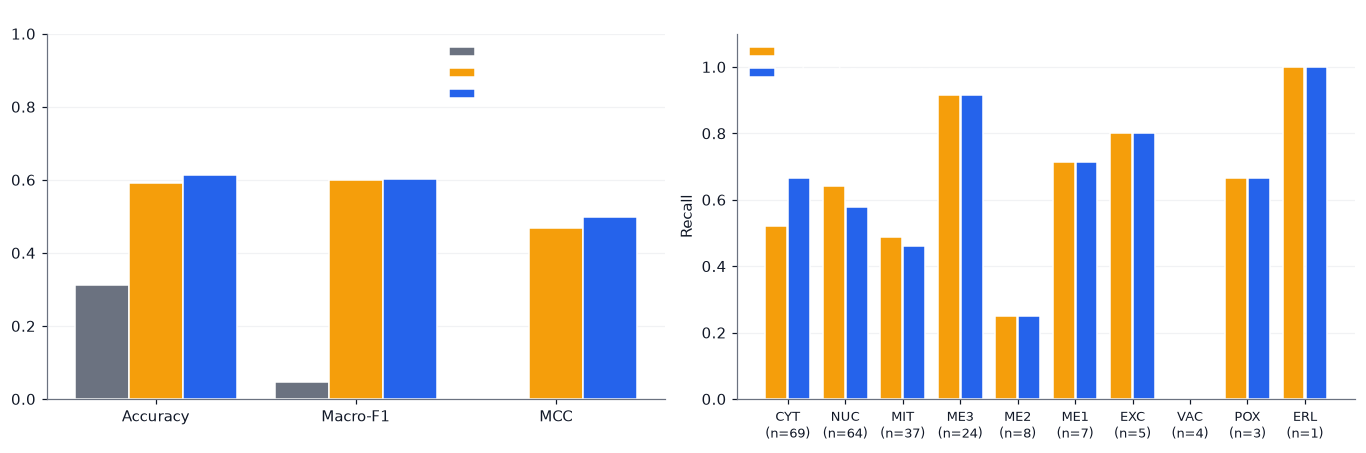

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
labels_m = ["accuracy", "macro_f1", "mcc"]
x = np.arange(len(labels_m)); w = 0.27
for offset, (name, res, color) in zip([-w, 0, w], [("Majority class", {"metrics": majority_metrics}, COLORS["gray"]),
                                                    ("Baseline + early stopping", test_base_y, COLORS["orange"]),
                                                    (f"Selected: {selected_yeast}", test_sel_y, COLORS["blue"])]):
    axes[0].bar(x + offset, [res["metrics"][k] for k in labels_m], w, color=color, label=name, edgecolor="white")
axes[0].set_xticks(x); axes[0].set_xticklabels(["Accuracy", "Macro-F1", "MCC"]); axes[0].set_ylim(0, 1)
axes[0].set_title("Test-set metrics (Yeast)"); axes[0].legend(fontsize=8.5, loc="upper right"); axes[0].grid(axis="x", visible=False)

def recall_per_class(res, data):
    cm = res["cm"].astype(float); support = cm.sum(axis=1)
    return np.divide(np.diag(cm), support, out=np.zeros_like(support), where=support > 0), support.astype(int)
r_base, support = recall_per_class(test_base_y, data_yeast)
r_sel, _ = recall_per_class(test_sel_y, data_yeast)
xc = np.arange(10)
axes[1].bar(xc - 0.2, r_base, 0.38, color=COLORS["orange"], label="Baseline + early stopping", edgecolor="white")
axes[1].bar(xc + 0.2, r_sel, 0.38, color=COLORS["blue"], label=f"Selected: {selected_yeast}", edgecolor="white")
axes[1].set_xticks(xc); axes[1].set_xticklabels([f"{c}\n(n={n})" for c, n in zip(CLASS_ORDER, support)], fontsize=8.5)
axes[1].set_ylim(0, 1.1); axes[1].set_ylabel("Recall"); axes[1].set_title("Per-class recall on the test set"); axes[1].legend(fontsize=8.5); axes[1].grid(axis="x", visible=False)
finish(fig, "13_yeast_test_results")

The test results tell the same story as the validation experiments, with the usual caveats: a few test samples per rare class make per-class recall an anecdote, and the bootstrap interval on macro-F1 is wide. If the selected regularized model and the baseline with early stopping are within each other's intervals, the honest conclusion is that **on this small, low-dimensional problem regularization changes little once early stopping is used** — an important and perfectly legitimate result.

# Part IV — Dataset 2: Tumour gene expression ($p \gg n$)

## 14. The dataset

*Gene expression cancer RNA-Seq* (Fiorini, 2016, UCI) is a random extraction of the **TCGA Pan-Cancer RNA-Seq (HiSeq)** project (Weinstein *et al.*, 2013). It contains the expression levels of **20,531 genes** (columns `gene_0` … `gene_20530`; anonymized names) for **801 tumour samples** of five cancer types:

| Code | Cancer type |
|---|---|
| `BRCA` | Breast invasive carcinoma |
| `KIRC` | Kidney renal clear cell carcinoma |
| `LUAD` | Lung adenocarcinoma |
| `PRAD` | Prostate adenocarcinoma |
| `COAD` | Colon adenocarcinoma |

The licence is CC BY 4.0 (full citation in the references). The task is to predict the cancer type from the expression profile.

**Why this is a different regime from Yeast.** There are 20,531 features but only 801 samples. A network with even a modest first layer has hundreds of thousands of parameters and can memorize every training tumour; whether it *generalizes* depends on regularization, feature selection, and honest validation.

The cell below looks for `data.csv` and `labels.csv` in `data/tcga_pancan/`. If they are missing, it downloads the archive (about 70 MB) and extracts it. If your computer has no internet access, download `TCGA-PANCAN-HiSeq-801x20531.tar.gz` from the UCI page and put either the archive or the two extracted CSV files into that folder.

In [35]:

import os
import tarfile
import pandas as pd


# Dataset configuration
GENE_DIR = "."

GENE_ARCHIVE = "TCGA-PANCAN-HiSeq-801x20531.tar.gz"
GENE_ARCHIVE = os.path.join(
    GENE_DIR,
    "TCGA-PANCAN-HiSeq-801x20531.tar.gz"
)

# Original dataset source:
# https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq


def _find_csvs(root):
    """Find data.csv and labels.csv inside the dataset directory."""

    found = {}

    for dirpath, _, files in os.walk(root):
        for filename in files:
            if filename in ("data.csv", "labels.csv"):
                found[filename] = os.path.join(
                    dirpath, filename
                )

    return found


def _safe_extract(archive_path, root):
    """Validate archive paths and safely extract the TAR archive."""

    root_real = os.path.realpath(root)

    with tarfile.open(archive_path, "r:*") as tar:

        members = tar.getmembers()

        for member in members:
            name = member.name.replace("\\", "/")

            # Reject absolute paths and Windows drive paths
            if name.startswith("/") or (
                len(name) >= 2 and name[1] == ":"
            ):
                raise RuntimeError(
                    f"Unsafe archive path: {member.name}"
                )

            # Reject symbolic and hard links
            if member.issym() or member.islnk():
                raise RuntimeError(
                    f"Archive links are not allowed: {member.name}"
                )

            target = os.path.realpath(
                os.path.join(root, name)
            )

            if os.path.commonpath(
                [root_real, target]
            ) != root_real:
                raise RuntimeError(
                    f"Unsafe archive path: {member.name}"
                )

        tar.extractall(root)


def load_gene_expression():
    """Load TCGA-PANCAN gene expression data and labels."""

    os.makedirs(GENE_DIR, exist_ok=True)

    # Check whether CSV files are already extracted
    found = _find_csvs(GENE_DIR)

    if "data.csv" not in found or "labels.csv" not in found:

        # Check local archive
        if not os.path.exists(GENE_ARCHIVE):
            raise FileNotFoundError(
                f"Dataset archive not found: {GENE_ARCHIVE}"
            )

        print("Extracting TCGA-PANCAN dataset...")

        try:
            _safe_extract(GENE_ARCHIVE, GENE_DIR)

        except (tarfile.TarError, EOFError, OSError) as error:
            raise RuntimeError(
                "The dataset archive is corrupted or incomplete. "
                "Please check the local TAR file."
            ) from error

        # Locate extracted CSV files
        found = _find_csvs(GENE_DIR)

    # Verify required files
    assert "data.csv" in found, "data.csv was not found."
    assert "labels.csv" in found, "labels.csv was not found."

    print("Loading gene expression matrix...")

    # Load expression matrix
    expression = pd.read_csv(
        found["data.csv"],
        index_col=0
    )

    # Load sample labels
    labels = pd.read_csv(
        found["labels.csv"],
        index_col=0
    )["Class"]

    # Validate sample ID alignment
    assert expression.index.equals(labels.index), (
        "Sample IDs of data.csv and labels.csv do not match."
    )

    return expression, labels


# Load dataset
expression_df, labels_series = load_gene_expression()

# Display dataset information
print("\nDataset loaded successfully!")
print("Expression matrix:", expression_df.shape)
print("Labels:", labels_series.shape)
print("\nClass distribution:")
print(labels_series.value_counts())


Extracting TCGA-PANCAN dataset...
Loading gene expression matrix...

Dataset loaded successfully!
Expression matrix: (801, 20531)
Labels: (801,)

Class distribution:
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


In [36]:
GENE_CLASSES = ["BRCA", "KIRC", "LUAD", "PRAD", "COAD"]
GENE_COLORS = dict(zip(GENE_CLASSES, [COLORS["blue"], COLORS["orange"], COLORS["green"], COLORS["purple"], COLORS["pink"]]))

assert expression_df.shape == (801, 20531), expression_df.shape
assert set(labels_series) == set(GENE_CLASSES)

X_gene_all = expression_df.to_numpy(dtype="float32")
y_gene_all = labels_series.map({c: i for i, c in enumerate(GENE_CLASSES)}).to_numpy(dtype="int32")
del expression_df                                      # free memory

print("Missing values        :", int(np.isnan(X_gene_all).sum()))
print("Value range           :", round(float(X_gene_all.min()), 2), "to", round(float(X_gene_all.max()), 2))
print("Fraction of exact zeros:", round(float((X_gene_all == 0).mean()), 3))
print("Genes that are constant in all samples:", int((X_gene_all.std(axis=0) == 0).sum()))
print("Class counts:", dict(zip(GENE_CLASSES, np.bincount(y_gene_all).tolist())))

gene_split = stratified_split_indices(y_gene_all)
tr_g, va_g, te_g = gene_split
print("\nTraining / validation / test:", len(tr_g), "/", len(va_g), "/", len(te_g))

Missing values        : 0
Value range           : 0.0 to 20.78
Fraction of exact zeros: 0.142
Genes that are constant in all samples: 267
Class counts: {'BRCA': 300, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136, 'COAD': 78}

Training / validation / test: 561 / 120 / 120


### 14.1 Exploration (training samples only)

Gene selection uses the data too, so the exploration below, the choice of the features, and the normalization statistics all use the **training partition only**.

**Variance filter.** Most of the 20,531 genes vary little across tumours, or are barely expressed. We keep the $K = 2000$ genes with the highest variance across the *training* samples. This is an **unsupervised** filter (it does not look at the labels), but it still must not use validation or test samples, otherwise their distribution would influence which features the model sees.

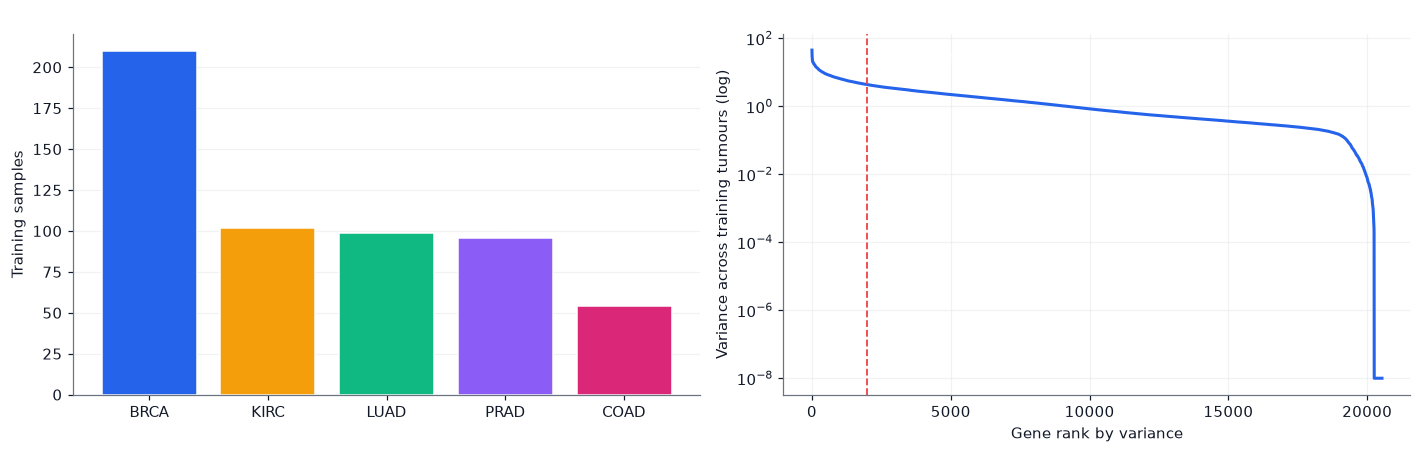

Selected 2000 of 20531 genes. Training samples: 561 -> features per sample / samples = 3.6


In [37]:
GENE_TOP_K = 2000
data_gene = make_data(X_gene_all, y_gene_all, tr_g, va_g, te_g, n_classes=5, class_names=GENE_CLASSES, select_top_k=GENE_TOP_K)

train_var = X_gene_all[tr_g].var(axis=0)
order_var = np.sort(train_var)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
counts_g = np.bincount(y_gene_all[tr_g], minlength=5)
bars = axes[0].bar(GENE_CLASSES, counts_g, color=[GENE_COLORS[c] for c in GENE_CLASSES], edgecolor="white")
for bar, c in zip(bars, counts_g):
    axes[0].text(bar.get_x() + bar.get_width() / 2, c + 4, str(c), ha="center", fontsize=9)
axes[0].set_ylabel("Training samples"); axes[0].set_title("Class distribution (training set)"); axes[0].grid(axis="x", visible=False)

axes[1].semilogy(np.arange(1, len(order_var) + 1), np.maximum(order_var, 1e-8), color=COLORS["blue"])
axes[1].axvline(GENE_TOP_K, color=COLORS["red"], linestyle="--", linewidth=1.2)
axes[1].annotate(f"keep the top {GENE_TOP_K}", (GENE_TOP_K, order_var[GENE_TOP_K]), textcoords="offset points", xytext=(10, 14), fontsize=9)
axes[1].set_xlabel("Gene rank by variance"); axes[1].set_ylabel("Variance across training tumours (log)")
axes[1].set_title("Most genes vary little between tumours")
finish(fig, "14_gene_overview")
print(f"Selected {GENE_TOP_K} of {X_gene_all.shape[1]} genes. Training samples: {len(tr_g)} -> features per sample / samples = {GENE_TOP_K / len(tr_g):.1f}")

C:\Users\mobin\AppData\Local\Temp\ipykernel_17588\3284237777.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=pad)


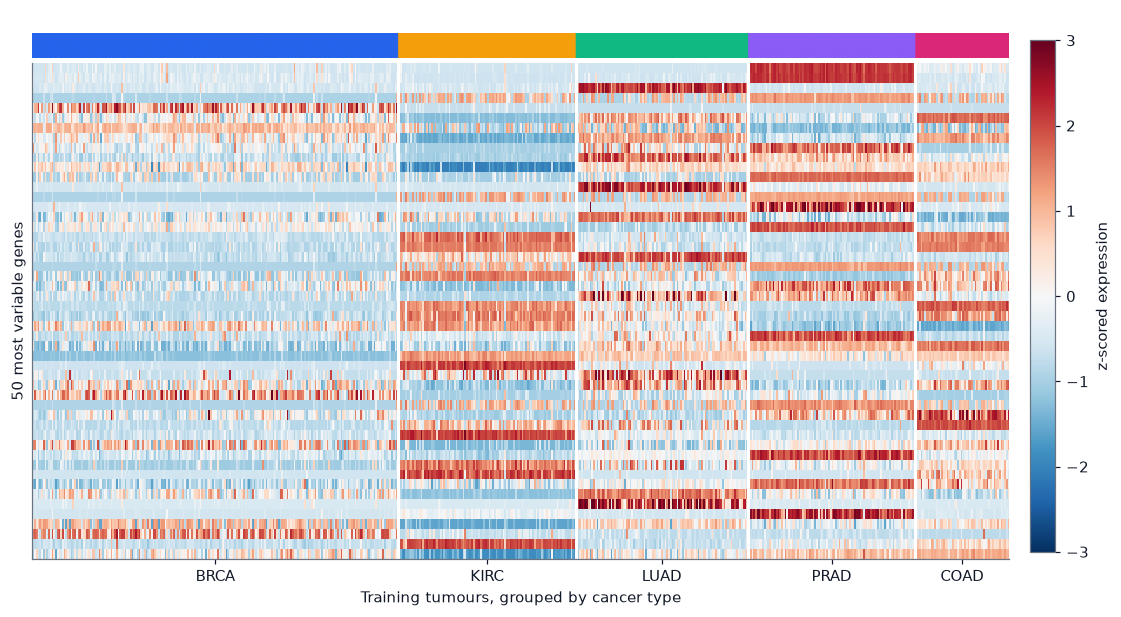

In [38]:
# Heatmap of the 50 most variable genes (z-scored per gene), samples grouped by cancer type.
top50 = np.argsort(-train_var)[:50]
order_samples = np.argsort(y_gene_all[tr_g], kind="stable")
M = X_gene_all[tr_g][order_samples][:, top50]
M = (M - M.mean(axis=0)) / (M.std(axis=0) + 1e-8)
class_strip = y_gene_all[tr_g][order_samples]

fig = plt.figure(figsize=(12, 6.2))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 20], hspace=0.02)
ax_strip = fig.add_subplot(gs[0]); ax_heat = fig.add_subplot(gs[1])
from matplotlib.colors import to_rgb
strip_rgb = np.array([[to_rgb(GENE_COLORS[GENE_CLASSES[c]]) for c in class_strip]])
ax_strip.imshow(strip_rgb, aspect="auto"); ax_strip.set_axis_off()
image = ax_heat.imshow(M.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
ax_heat.grid(False); ax_heat.set_xlabel("Training tumours, grouped by cancer type"); ax_heat.set_ylabel("50 most variable genes")
boundaries = np.cumsum(counts_g)[:-1]
for b in boundaries:
    ax_heat.axvline(b - 0.5, color="white", linewidth=2)
centers = np.cumsum(counts_g) - counts_g / 2
ax_heat.set_xticks(centers - 0.5); ax_heat.set_xticklabels(GENE_CLASSES); ax_heat.set_yticks([])
fig.colorbar(image, ax=[ax_strip, ax_heat], fraction=0.025, pad=0.02, label="z-scored expression")
ax_strip.set_title("Expression of the 50 most variable genes, tumours grouped by cancer type", loc="left")
finish(fig, "15_gene_heatmap")

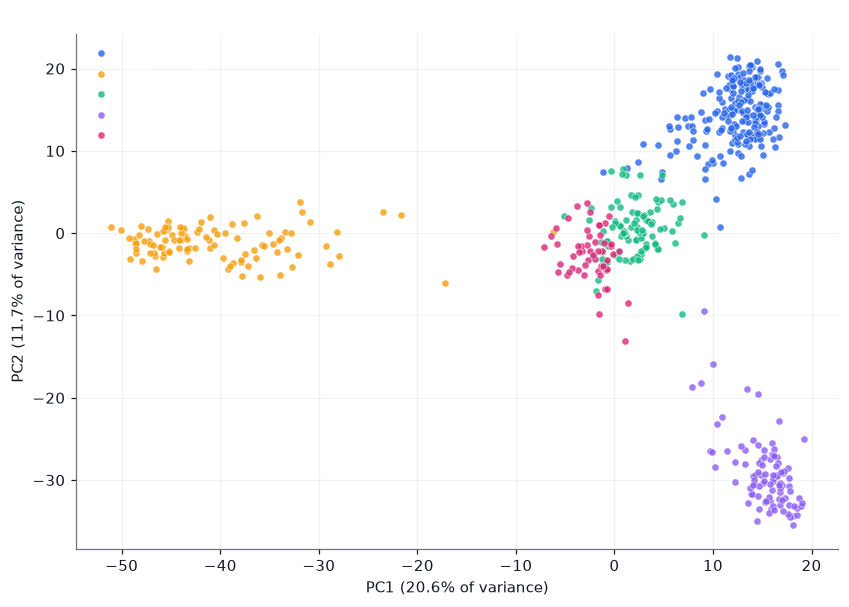

In [39]:
# PCA of the selected genes (standardized with training statistics), training samples only.
Xs = data_gene["X_train"]
Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
U, S, Vt = np.linalg.svd(Xs, full_matrices=False)
scores = Xs @ Vt[:2].T
explained = S**2 / np.sum(S**2)

fig, ax = plt.subplots(figsize=(7.8, 5.6))
for k, c in enumerate(GENE_CLASSES):
    mask = data_gene["y_train"] == k

    ax.scatter(scores[mask, 0], scores[mask, 1], s=22, alpha=0.8, color=GENE_COLORS[c], edgecolor="white", linewidth=0.4, label=f"{c} (n={mask.sum()})")
ax.set_xlabel(f"PC1 ({100 * explained[0]:.1f}% of variance)"); ax.set_ylabel(f"PC2 ({100 * explained[1]:.1f}% of variance)")
ax.set_title("Two principal components already separate most cancer types"); ax.legend(loc="best", fontsize=8.5)
finish(fig, "16_gene_pca")

The cancer types form visible clusters even in two dimensions: this is a problem with **strong signal**, so we expect high accuracy from any reasonable model. The interesting questions are therefore different from those of Yeast: *how confident and stable is the model, how many samples does it need, and how do the regularization techniques behave when there are far more weights than samples?*

## 15. Experiment G1 — regularization ablation when $p \gg n$

We use a network with two hidden layers (128 and 64 units) on the 2000 selected genes. The first layer alone has $2000 \times 128 + 128 = 256{,}128$ weights for 561 training samples. Dropout is 0.5 (this network is much larger relative to the data), and the L1 penalty is weaker because there are many more weights.

Trainable parameters of the baseline network: 264,709  |  training samples: 561  |  parameters per sample: 472
Done in 213 s


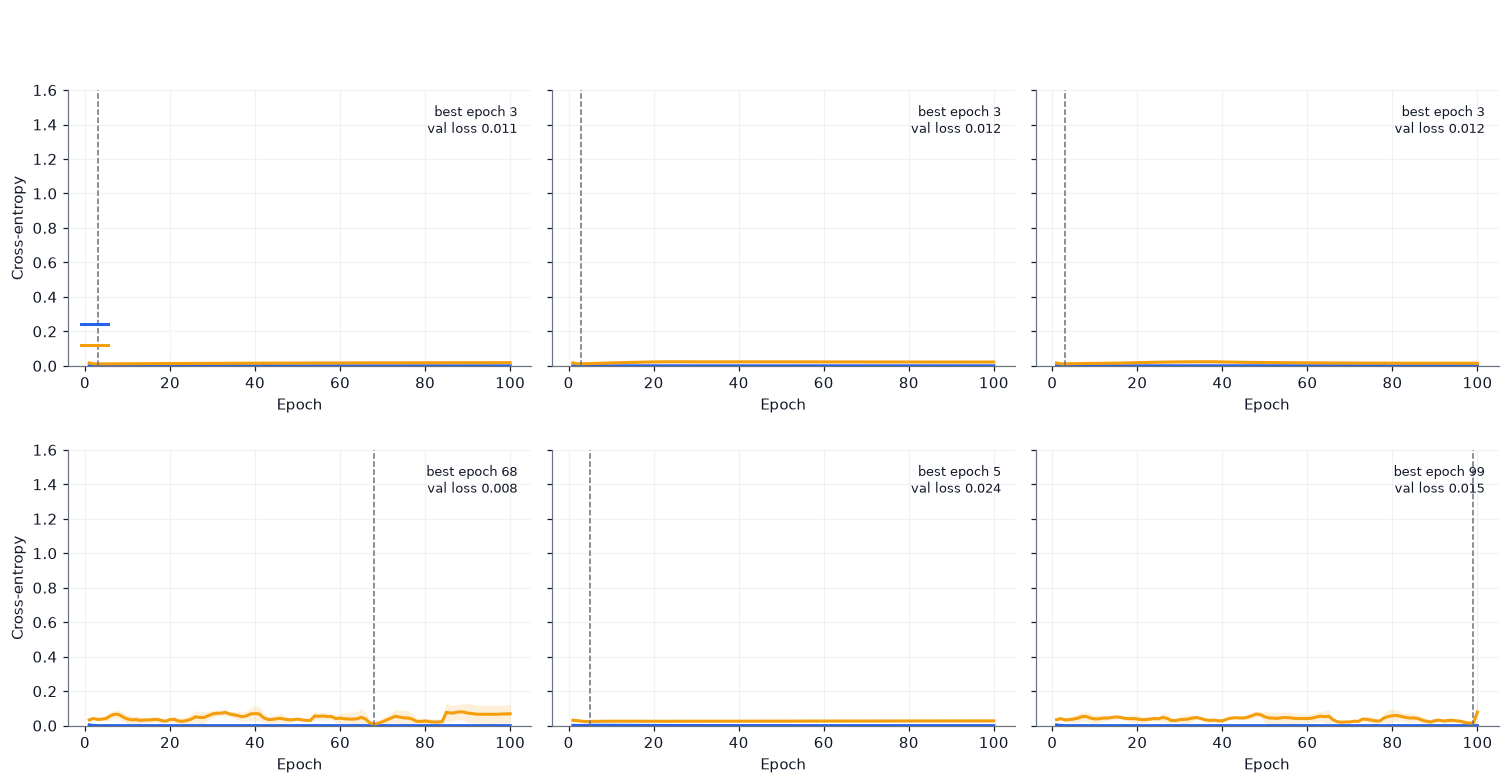

In [40]:
BASE_GENE = dict(hidden_units=(128, 64))
gene_configs = {
    "Baseline":     dict(BASE_GENE),
    "L2 (1e-3)":    dict(BASE_GENE, l2=1e-3),
    "L1 (5e-5)":    dict(BASE_GENE, l1=5e-5),
    "Dropout 0.5":  dict(BASE_GENE, dropout=0.5),
    "BatchNorm":    dict(BASE_GENE, batch_norm=True),
    "Dropout + L2": dict(BASE_GENE, dropout=0.5, l2=1e-3),
}
n_params_gene = count_trainable(build_classifier(data_gene["X_train"], 5, **BASE_GENE))
print(f"Trainable parameters of the baseline network: {n_params_gene:,}  |  training samples: {len(data_gene['y_train'])}"
      f"  |  parameters per sample: {n_params_gene / len(data_gene['y_train']):.0f}")

EPOCHS_GENE = epochs_for(100)
results_gene = {}
t0 = time.time()
for name, config in gene_configs.items():
    results_gene[name] = run_many(data_gene, config, EPOCHS_GENE, optimizer="Adam", learning_rate=1e-3)
print(f"Done in {time.time() - t0:.0f} s")
plot_curve_grid(results_gene, list(gene_configs), "Gene expression: training and validation loss for each configuration (mean \u00b1 SD over seeds)",
                "17_gene_ablation_curves", ylim=(0, 1.6))

,parameters,best epoch,min val loss,val macro-F1 @ best,val acc @ best,final val loss,final train loss,final gap (val − train)
Baseline,264709,3,0.011 ± 0.006,0.998 ± 0.003,0.997,0.019 ± 0.008,0.000,0.019
L2 (1e-3),264709,2,0.011 ± 0.006,0.998 ± 0.003,0.997,0.022 ± 0.001,0.000,0.022
L1 (5e-5),264709,28,0.010 ± 0.005,0.995 ± 0.007,0.994,0.015 ± 0.003,0.000,0.015
Dropout 0.5,264709,40,0.004 ± 0.003,1.000 ± 0.000,1.000,0.069 ± 0.053,0.000,0.069
BatchNorm,264901,20,0.020 ± 0.003,0.990 ± 0.003,0.989,0.028 ± 0.006,0.000,0.028
Dropout + L2,264709,52,0.004 ± 0.003,0.998 ± 0.003,0.997,0.079 ± 0.087,0.000,0.079


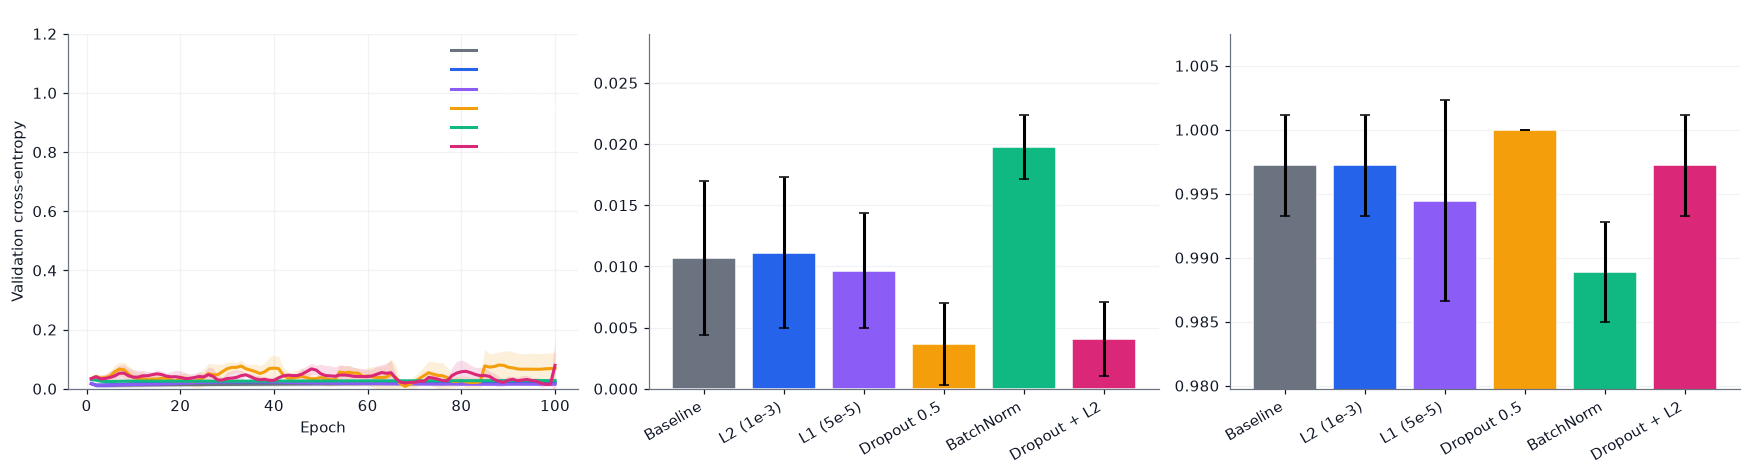

In [41]:
summary_gene = summarize(results_gene)
display(summary_gene)

names_g = list(gene_configs)
palette = [COLORS["gray"], COLORS["blue"], COLORS["purple"], COLORS["orange"], COLORS["green"], COLORS["pink"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for name, color in zip(names_g, palette):
    band(axes[0], results_gene[name]["val_loss"], color, name)
axes[0].set_ylim(0, 1.2); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Validation cross-entropy")
axes[0].set_title("Validation loss"); axes[0].legend(fontsize=8)
for ax, key, label in zip(axes[1:], ["val_loss", "val_acc"], ["Validation loss at the best epoch", "Validation accuracy at the best epoch"]):
    means = [per_seed(results_gene, n, key).mean() for n in names_g]
    sds = [per_seed(results_gene, n, key).std() for n in names_g]
    ax.bar(range(len(names_g)), means, yerr=sds, color=palette, capsize=3, edgecolor="white")
    ax.set_xticks(range(len(names_g))); ax.set_xticklabels(names_g, rotation=30, ha="right"); ax.set_title(label); ax.grid(axis="x", visible=False)
    lo, hi = min(m - s for m, s in zip(means, sds)), max(m + s for m, s in zip(means, sds))
    ax.set_ylim(max(0, lo - 0.3 * (hi - lo)), hi + 0.3 * (hi - lo))
finish(fig, "18_gene_ablation_summary")

What typically happens in this regime (compare with your numbers):

- **Accuracy saturates.** Because the signal is strong, almost every configuration reaches high validation accuracy; the validation **loss** is the more sensitive measure, since it also rewards well-calibrated confidence.
- The unregularized network drives its **training loss to almost zero** within a few epochs — it memorizes 561 tumours easily — yet it still generalizes well, because a strong signal remains after memorization. Zero training error therefore does **not** automatically mean bad generalization; what matters is the validation curve.
- **Regularization changes the shape of the validation curve**: with L2 or Dropout the validation loss usually settles lower and drifts less with more epochs, which makes the result less dependent on exactly when training stops.
- **L1** mainly sparsifies the first-layer weights; with thousands of redundant genes this is attractive for interpretation, but it rarely improves accuracy by itself.
- **BatchNorm** with a small batch (32) and a very wide input can make training noisier; its benefit is mostly faster optimization, not better generalization here.

## 16. Experiment G2 — how much data does the model need?

A different kind of learning curve plots performance against the **number of training samples**. Regularization matters most when data are scarce. We train the baseline and the Dropout + L2 network on stratified subsets of the training set (10% to 100%), always evaluating on the same validation set. Gene selection and normalization are recomputed from the **subset** each time, so that no training information beyond the subset is used.

Done in 165 s


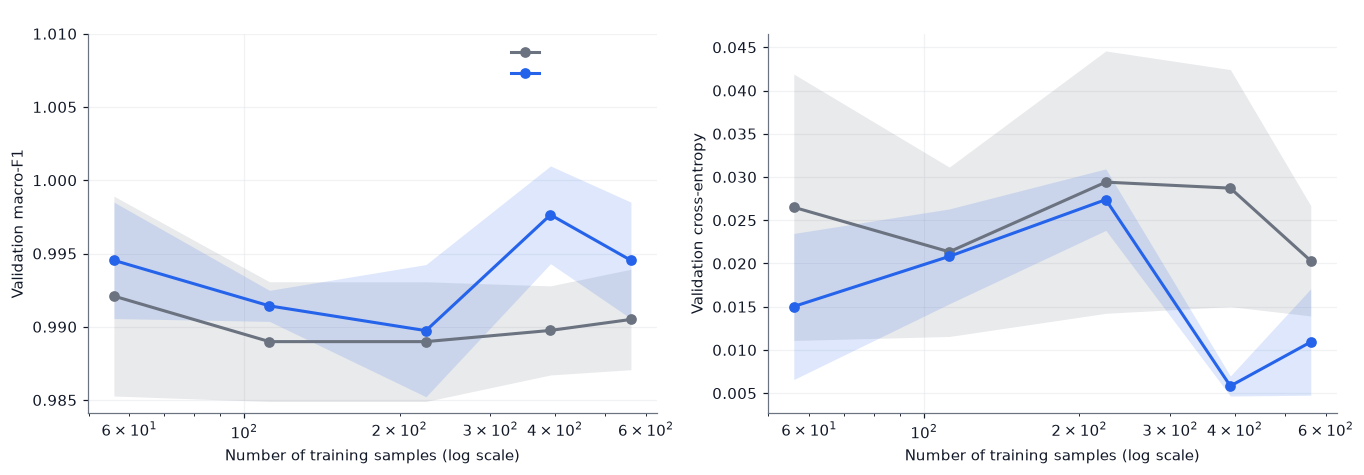

,Baseline,Dropout + L2
10%,"n=56: F1 0.992, loss 0.026","n=56: F1 0.995, loss 0.015"
20%,"n=112: F1 0.989, loss 0.021","n=112: F1 0.991, loss 0.021"
40%,"n=225: F1 0.989, loss 0.029","n=225: F1 0.990, loss 0.027"
70%,"n=392: F1 0.990, loss 0.029","n=392: F1 0.998, loss 0.006"
100%,"n=561: F1 0.991, loss 0.020","n=561: F1 0.995, loss 0.011"


In [42]:
def stratified_subsample(labels, fraction, seed):
    """Subsample a fraction of each class (at least 3 per class)."""
    r = np.random.default_rng(seed)
    chosen = []
    for c in np.unique(labels):
        idx = r.permutation(np.flatnonzero(labels == c))
        chosen.append(idx[:max(3, int(round(fraction * len(idx))))])
    return np.concatenate(chosen)

fractions = [0.1, 0.2, 0.4, 0.7, 1.0]
EPOCHS_SIZE = epochs_for(60)
size_configs = {"Baseline": gene_configs["Baseline"], "Dropout + L2": gene_configs["Dropout + L2"]}

size_results = {name: {"n": [], "f1": [], "loss": [], "acc": []} for name in size_configs}
t0 = time.time()
for fraction in fractions:
    per_seed_stats = {name: {"f1": [], "loss": [], "acc": []} for name in size_configs}
    for seed in range(SEED, SEED + N_SEEDS):
        sub = tr_g[stratified_subsample(y_gene_all[tr_g], fraction, seed)]
        d_sub = make_data(X_gene_all, y_gene_all, sub, va_g, te_g, n_classes=5, class_names=GENE_CLASSES, select_top_k=GENE_TOP_K)
        for name, config in size_configs.items():
            run = run_experiment(d_sub, config, seed, EPOCHS_SIZE)
            best = int(run["val_loss"].argmin())
            for key, curve in (("f1", run["val_f1"]), ("loss", run["val_loss"]), ("acc", run["val_acc"])):
                per_seed_stats[name][key].append(curve[best])
    for name in size_configs:
        size_results[name]["n"].append(len(d_sub["y_train"]))
        for key in ("f1", "loss", "acc"):
            size_results[name][key].append((np.mean(per_seed_stats[name][key]), np.std(per_seed_stats[name][key])))
print(f"Done in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for name, color in zip(size_configs, [COLORS["gray"], COLORS["blue"]]):
    n = np.array(size_results[name]["n"])
    for ax, key, label in zip(axes, ["f1", "loss"], ["Validation macro-F1", "Validation cross-entropy"]):
        m = np.array([v[0] for v in size_results[name][key]]); s = np.array([v[1] for v in size_results[name][key]])
        ax.plot(n, m, marker="o", color=color, label=name)
        ax.fill_between(n, m - s, m + s, color=color, alpha=0.15, linewidth=0)
        ax.set_xscale("log"); ax.set_xlabel("Number of training samples (log scale)"); ax.set_ylabel(label)
axes[0].set_title("Macro-F1 against training-set size"); axes[1].set_title("Validation loss against training-set size")
axes[0].legend(); axes[0].set_ylim(top=1.01)
finish(fig, "19_gene_sample_size")
display(pd.DataFrame({name: [f"n={n}: F1 {v[0]:.3f}, loss {l[0]:.3f}" for n, v, l in zip(size_results[name]["n"], size_results[name]["f1"], size_results[name]["loss"])]
                      for name in size_configs}, index=[f"{int(f * 100)}%" for f in fractions]))

With very few samples per class the models are far from perfect, the seed-to-seed spread is large, and the gap between regularized and unregularized training is largest; as the training set grows, both converge towards the same high performance. **This is the practical meaning of regularization: it buys back some of the performance that scarcity of data takes away.**

## 17. Selecting a configuration and evaluating on the test set

The same pre-declared rule as for Yeast: choose the configuration with the lowest mean minimum validation loss, train it once with early stopping, and evaluate on the test set. The unregularized baseline with early stopping is the reference.

In [43]:
selected_gene = min(results_gene, key=lambda n: min_val_loss_mean(results_gene, n))
print("Mean minimum validation loss:", {n: round(min_val_loss_mean(results_gene, n), 4) for n in results_gene})
print("Selected configuration:", selected_gene)

model_sel_g, hist_sel_g = train_final(data_gene, gene_configs[selected_gene], name="gene_selected")
model_base_g, hist_base_g = train_final(data_gene, gene_configs["Baseline"], name="gene_baseline_es")
test_sel_g = evaluate_on_test(data_gene, model_sel_g)
test_base_g = evaluate_on_test(data_gene, model_base_g)

majority_pred_g = np.full_like(data_gene["y_test"], np.bincount(data_gene["y_train"]).argmax())
majority_metrics_g = summary_metrics(confusion_matrix_np(data_gene["y_test"], majority_pred_g, 5))

test_table_g = pd.DataFrame({
    "Majority class": {**majority_metrics_g, "test loss": np.nan},
    "Baseline + early stopping": {**test_base_g["metrics"], "test loss": test_base_g["test_loss"]},
    f"Selected: {selected_gene} + early stopping": {**test_sel_g["metrics"], "test loss": test_sel_g["test_loss"]},
}).round(3)
display(test_table_g)
print(f"Selected model, 95% bootstrap intervals -> accuracy [{test_sel_g['acc_ci'][0]:.3f}, {test_sel_g['acc_ci'][1]:.3f}], "
      f"macro-F1 [{test_sel_g['f1_ci'][0]:.3f}, {test_sel_g['f1_ci'][1]:.3f}]")

Mean minimum validation loss: {'Baseline': 0.0107, 'L2 (1e-3)': 0.0111, 'L1 (5e-5)': 0.0097, 'Dropout 0.5': 0.0037, 'BatchNorm': 0.0198, 'Dropout + L2': 0.004}
Selected configuration: Dropout 0.5


,Majority class,Baseline + early stopping,Selected: Dropout 0.5 + early stopping
accuracy,0.375,1.000,1.0
macro_f1,0.109,1.000,1.0
mcc,0.000,1.000,1.0
test loss,NaN,0.001,0.0


Selected model, 95% bootstrap intervals -> accuracy [1.000, 1.000], macro-F1 [1.000, 1.000]


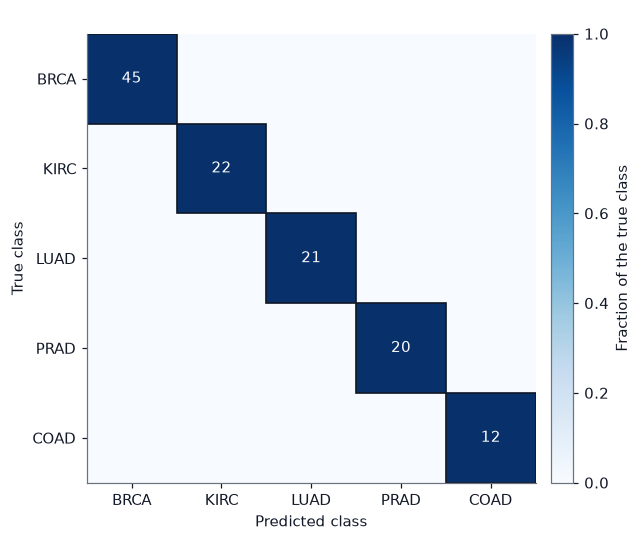

In [44]:
def plot_confusion(cm, labels, title, name):
    cm = np.asarray(cm); K = len(labels)
    norm = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros(cm.shape, dtype=float), where=cm.sum(axis=1, keepdims=True) > 0)
    fig, ax = plt.subplots(figsize=(5.8, 5.0))
    image = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(K)); ax.set_xticklabels(labels); ax.set_yticks(range(K)); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title); ax.grid(False)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}" if cm[i, j] else "", ha="center", va="center", fontsize=10,
                    color="white" if norm[i, j] > 0.55 else COLORS["dark"])
        ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=COLORS["dark"], linewidth=1.1))
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03, label="Fraction of the true class")
    finish(fig, name)

plot_confusion(test_sel_g["cm"], GENE_CLASSES, f"Test confusion matrix: {selected_gene}", "20_gene_test_confusion")

Interpretation notes for the gene-expression result:

- A very high test accuracy (if you see one) shows that **these five cancer types are easy to tell apart from expression**, not that tumour classification is solved. The dataset contains five very different tissues; distinguishing, say, subtypes of the same cancer, or tumours from several hospitals with batch effects, is far harder.
- The test set has about 120 tumours, so one error changes the accuracy by almost one percentage point; the bootstrap interval expresses exactly that uncertainty.
- Selecting genes by variance on the training set is a *legitimate* preprocessing step here because it does not use validation or test data. Selecting genes using **all** samples, or using the labels of all samples, is one of the most common leakage mistakes in published genomics studies (Notebook 07).

# Part V — Synthesis

## 18. What did the two datasets teach us?

train samples  features  parameters  \
dataset         configuration                                        
Yeast           Baseline                1040         8       18954   
                L2 (1e-3)               1040         8       18954   
                L1 (1e-4)               1040         8       18954   
                Dropout 0.3             1040         8       18954   
                BatchNorm               1040         8       19210   
                Dropout + L2            1040         8       18954   
Gene expression Baseline                 561      2000      264709   
                L2 (1e-3)                561      2000      264709   
                L1 (5e-5)                561      2000      264709   
                Dropout 0.5              561      2000      264709   
                BatchNorm                561      2000      264901   
                Dropout + L2             561      2000      264709   

                               min val loss  final gap (val − train)  
dataset         configuration                                         
Yeast           Baseline              1.086                    1.356  
                L2 (1e-3)             1.078                    0.768  
                L1 (1e-4)             1.083                    1.009  
                Dropout 0.3           1.047                    0.494  
                BatchNorm             1.086                    1.431  
                Dropout + L2          1.041                    0.339  
Gene expression Baseline              0.011                    0.019  
                L2 (1e-3)             0.011                    0.022  
                L1 (5e-5)             0.010                    0.015  
                Dropout 0.5           0.004                    0.069  
                BatchNorm             0.020                    0.028  
                Dropout + L2          0.004                    0.079

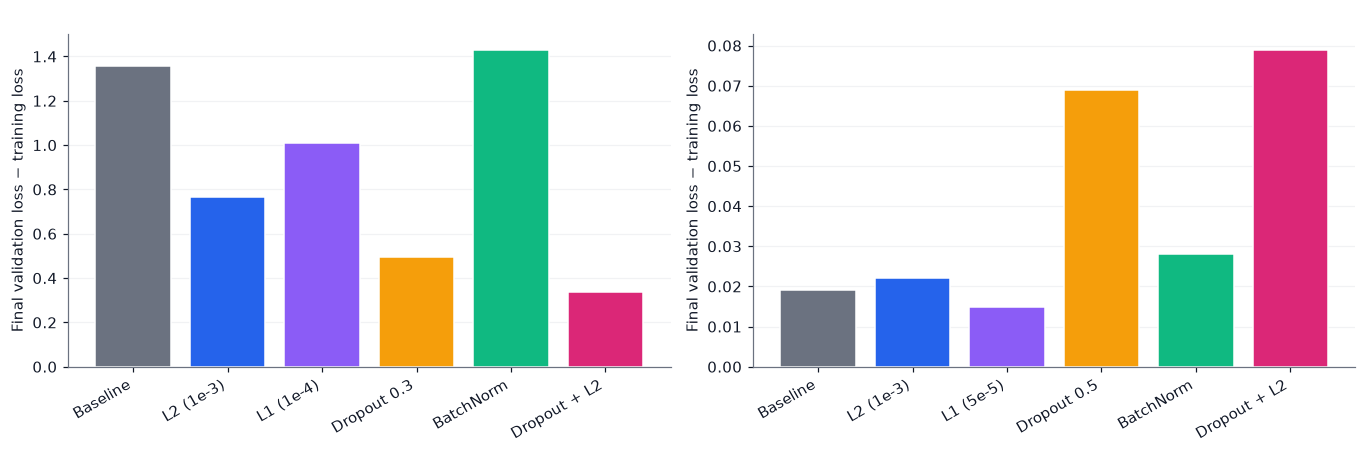

In [45]:
def gap_and_best(results, name):
    r = results[name]; idx = r["val_loss"].argmin(axis=1)
    best = np.mean([r["val_loss"][i][idx[i]] for i in range(len(idx))])
    final_gap = np.mean(r["val_loss"][:, -1] - r["train_loss"][:, -1])
    return best, final_gap

rows = []
for dataset, results, d, base_cfg in [("Yeast", results_yeast, data_yeast, BASE_YEAST), ("Gene expression", results_gene, data_gene, BASE_GENE)]:
    for name in results:
        best, gap = gap_and_best(results, name)
        rows.append({"dataset": dataset, "configuration": name, "train samples": len(d["y_train"]), "features": d["X_train"].shape[1],
                     "parameters": results[name]["n_params"], "min val loss": round(best, 3), "final gap (val \u2212 train)": round(gap, 3)})
synthesis = pd.DataFrame(rows)
display(synthesis.set_index(["dataset", "configuration"]))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for ax, (dataset, sub) in zip(axes, synthesis.groupby("dataset", sort=False)):
    colors_ = [COLORS["gray"], COLORS["blue"], COLORS["purple"], COLORS["orange"], COLORS["green"], COLORS["pink"]]
    ax.bar(range(len(sub)), sub["final gap (val \u2212 train)"], color=colors_[:len(sub)], edgecolor="white")
    ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub["configuration"], rotation=30, ha="right")
    ax.set_ylabel("Final validation loss \u2212 training loss"); ax.set_title(f"{dataset}: size of the generalization gap at the end"); ax.grid(axis="x", visible=False)
finish(fig, "21_synthesis_gap")

### 18.1 A practical recipe

| Step | Recommendation | Why |
|---|---|---|
| Inputs | standardize with **training** statistics (a `Normalization` layer) | conditioning (Notebook 05), no leakage |
| Optimizer | start with Adam, $\eta = 10^{-3}$; tune $\eta$ on a log grid ($3\times$ steps) | the learning rate matters more than the optimizer family |
| Schedule | reduce the rate on plateau, or cosine decay, for the final refinement | removes the noise floor of a constant step |
| Batch size | 32–128 for small datasets | noise acts as regularization; large batches need larger $\eta$ |
| Stopping | always early stopping on the validation loss with restore of best weights | cheapest regularizer, often the most effective |
| Capacity | start small; increase only if the training error itself is too high | overfitting is easier to prevent than to cure |
| Regularization | small L2 and/or Dropout; BatchNorm when depth or width make optimization hard | each shapes the validation curve differently (Sections 12 and 15) |
| Evaluation | several seeds; report mean ± SD; touch the test set once | single runs cannot separate effects from luck |
| High-dimensional data | filter features **inside** the training partition; regularize; check the learning curve against the number of samples | prevents leakage and over-confidence |

### 18.2 Limitations of these experiments

1. **Small grids.** We tried few learning rates and one value of each regularization strength. Real tuning explores more values, ideally with a random or Bayesian search, and re-tunes the learning rate when the regularizer changes.
2. **Few seeds.** Three seeds give a rough idea of the variability, not a reliable standard deviation. Differences smaller than the seed-to-seed spread should not be interpreted.
3. **One split per dataset.** Validation losses were used to choose the configuration; cross-validation (Notebook 07) gives more reliable choices.
4. **Rare classes in Yeast** (5–50 proteins) make class-level conclusions unreliable.
5. **Gene expression** here is an easy problem (five distinct tissues); strong conclusions about harder molecular classification tasks (subtypes, treatment response, batch effects) cannot be drawn from it.
6. **Adam and weight decay.** Adding an L2 term to the loss is *not* equivalent to weight decay in adaptive optimizers; decoupled weight decay (AdamW) is the preferred form there (see the references).

## 19. What did we learn?

1. An epoch is $\lceil N/B\rceil$ iterations. The mini-batch gradient is **unbiased**, and its noise variance falls like $1/B$ (verified numerically).
2. Gradient descent is stable only for $\eta < 2/\lambda_{\max}$. **Schedules** let us use a large rate early and a small one late.
3. **Momentum** accumulates a velocity (effective rate $\eta/(1-\beta)$); **RMSprop** rescales each coordinate; **Adam** combines both with a **bias correction** derived from $\mathbb{E}[m_t] = (1-\beta_1^t)\mathbb{E}[g]$. Our NumPy implementations agree with Keras.
4. On real data, the **learning rate matters more than the optimizer**; fair comparisons tune the rate of each method.
5. **L2** shrinks weights proportionally (ridge, Gaussian prior; filter factors $s_i^2/(s_i^2+\lambda)$ fix collinearity). **L1** soft-thresholds and gives sparsity (Laplace prior).
6. **Dropout** keeps expected activations unchanged and, for linear models, equals an adaptive L2 penalty $\frac{p}{1-p}\sum w_j^2 z_j^2$ (verified by simulation).
7. **Batch normalization** normalizes with batch statistics in training and running averages at inference.
8. **Early stopping** behaves like ridge with $\alpha \approx 1/(\eta t)$ and is usually the most cost-effective regularizer.
9. **Yeast** (few features): the gains from regularization are modest once early stopping is used. **Gene expression** ($p \gg n$): the model can memorize the training set yet still generalize because the signal is strong; regularization matters most when training data are scarce.

### Key terms

| Term | Meaning |
|---|---|
| Iteration / epoch | One update / one pass over the training data |
| Mini-batch gradient | Gradient estimated on $B$ samples; unbiased, variance $\propto 1/B$ |
| Learning-rate schedule | A rule that changes $\eta$ during training |
| Momentum | Exponentially weighted sum of past gradients |
| Adaptive optimizer | Rescales each coordinate's step (RMSprop, Adam) |
| Bias correction | Division by $1-\beta^t$ to undo the zero initialization of moment estimates |
| Weight decay / L2 | Penalty $\tfrac{\lambda}{2}\lVert w\rVert^2$; shrinks weights |
| L1 | Penalty $\lambda\lVert w\rVert_1$; produces exact zeros |
| Dropout | Random masking of activations during training |
| Batch normalization | Normalization with batch statistics; running averages at inference |
| Early stopping | Stopping at the epoch of minimum validation loss |
| Generalization gap | Validation loss minus training loss |
| $p \gg n$ | More features than samples |

## 20. Exercises

### A. Mathematics

1. A dataset has $N = 4177$ samples and the batch size is 64. How many iterations are there in 50 epochs? What changes if the last incomplete batch is dropped?
2. Prove that the mini-batch gradient $g_S$ (uniform sampling without replacement) is unbiased. Why does the variance formula contain the factor $(N-B)/(N-1)$?
3. For $L(w) = \tfrac{1}{2}\lambda w^2$, find the learning rate that minimizes $|1 - \eta\lambda|$. For a quadratic with eigenvalues $\lambda_{\min}$ and $\lambda_{\max}$, find the learning rate minimizing the worst-case contraction factor $\max_i |1-\eta\lambda_i|$, and show that the resulting factor is $\frac{\kappa-1}{\kappa+1}$.
4. Show that with momentum and a constant gradient $g$, the velocity converges to $g/(1-\beta)$. What is the effective learning rate for $\beta = 0.99$?
5. Derive the bias correction of the second moment: if $\mathbb{E}[g_t^2] = c$ for all $t$, show $\mathbb{E}[v_t] = (1-\beta_2^t)\,c$.
6. Show that the first Adam step equals $-\eta\,g_1/(|g_1| + \varepsilon)$ coordinate-wise. Why is this potentially a problem for a coordinate whose gradient is tiny noise?
7. Derive the ridge solution $w_\lambda = (Z^{\top}Z + \lambda I)^{-1}Z^{\top}y$ and its expression in terms of the SVD of $Z$. Compute the filter factors for $s = 10$, $s = 0.1$ and $\lambda = 1$.
8. Derive the soft-thresholding rule by minimizing $\tfrac{1}{2}(w-z)^2 + \lambda|w|$ (consider the cases $w>0$, $w<0$, $w=0$ and the subgradient of $|w|$).
9. Prove $\mathbb{E}[m_j/(1-p)] = 1$ for $m_j \sim \operatorname{Bernoulli}(1-p)$, and compute $\operatorname{Var}(m_j/(1-p))$. Use it to prove the adaptive-L2 formula of Section 7.3.
10. Write the backward pass of batch normalization (the derivatives of the loss with respect to $x_i$, $\gamma$, $\beta$), using $\hat{x}_i$ and $\sigma_B$. *(Challenging.)*

### B. Programming

1. Reproduce the gradient-noise experiment of Section 4.1 for a **logistic regression** instead of least squares. Does the $1/B$ scaling still hold?
2. Add a cosine learning-rate schedule (`keras.optimizers.schedules.CosineDecay`) to the Yeast baseline and compare the final validation loss with a constant rate.
3. Implement **Nesterov momentum** (`keras.optimizers.SGD(momentum=0.9, nesterov=True)`) and add it to the toy comparison of Section 6.4 and to the Yeast optimizer grid.
4. Repeat the Yeast regularization ablation with `l2` in $\{10^{-4}, 10^{-3}, 10^{-2}\}$ and plot the minimum validation loss against $l2$. Which value is best, and what happens for a value that is too large?
5. Replace the L2 term by decoupled weight decay (`keras.optimizers.AdamW(weight_decay=...)`) and compare.
6. On the gene-expression data, change `GENE_TOP_K` to 100, 500, 2000, and 5000. How do validation loss and training time change?
7. Replace the variance filter by a filter that uses the **labels of all 801 samples** (for example, the top genes by ANOVA F-statistic computed on all samples) and evaluate on the *same* test set. How much better does it look? Explain why this number is not trustworthy.
8. Extend `run_many` to record the epoch at which the training accuracy first reaches 100%. How does it differ between configurations?

### C. Research thinking

1. In the gene-expression ablation, the unregularized network reaches near-zero training loss and still generalizes well. In what situations would you expect the same network to generalize badly?
2. Why can a model with higher validation *loss* have a higher validation *accuracy*? Which would you trust for choosing a model, and why?
3. A colleague reports a 99% accuracy for a tumour classifier after selecting the 100 most informative genes on the whole dataset and then splitting into training and test sets. Explain what is wrong and how to fix the protocol.
4. Design an experiment to decide whether Dropout or L2 is better for the gene-expression data, taking into account the interaction with the learning rate, the number of seeds, and the multiple-comparison problem.

## 21. Further exploration and references

### Datasets

- Nakai, K. (1991). *Yeast* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C5KG68> (CC BY 4.0).
- Fiorini, S. (2016). *Gene expression cancer RNA-Seq* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C5R88H> (CC BY 4.0).
- Weinstein, J. N., *et al.* (2013). The Cancer Genome Atlas Pan-Cancer analysis project. *Nature Genetics*, 45(10), 1113–1120.

### Methods

- Kingma, D. P. and Ba, J. (2015). Adam: a method for stochastic optimization. *ICLR*.
- Tieleman, T. and Hinton, G. (2012). Lecture 6.5 — RMSprop. *COURSERA: Neural Networks for Machine Learning*.
- Loshchilov, I. and Hutter, F. (2019). Decoupled weight decay regularization. *ICLR*.
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., and Salakhutdinov, R. (2014). Dropout: a simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15, 1929–1958.
- Wager, S., Wang, S., and Liang, P. (2013). Dropout training as adaptive regularization. *NeurIPS*.
- Ioffe, S. and Szegedy, C. (2015). Batch normalization: accelerating deep network training by reducing internal covariate shift. *ICML*.
- Santurkar, S., Tsipras, D., Ilyas, A., and Madry, A. (2018). How does batch normalization help optimization? *NeurIPS*.
- Prechelt, L. (1998). Early stopping — but when? In *Neural Networks: Tricks of the Trade*.
- Smith, L. N. (2017). Cyclical learning rates for training neural networks. *WACV*.
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society B*, 58(1), 267–288.

### Keras documentation

- [Optimizers](https://keras.io/api/optimizers/) and [learning-rate schedules](https://keras.io/api/optimizers/learning_rate_schedules/)
- [Regularizers](https://keras.io/api/layers/regularizers/)
- [Dropout](https://keras.io/api/layers/regularization_layers/dropout/) and [BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)
- [Callbacks: EarlyStopping, ReduceLROnPlateau](https://keras.io/api/callbacks/)

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 7 (regularization), chapter 8 (optimization), and chapter 5 (capacity, overfitting, bias and variance).
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the chapter on training deep neural networks.
- Chollet — *Deep Learning with Python*: the sections on overfitting, regularization, and the universal workflow of machine learning.
- Hastie, Tibshirani, and Friedman — *The Elements of Statistical Learning*: chapter 3 (ridge and lasso) and chapter 18 (high-dimensional problems, $p \gg n$).

---

## Next notebook

**07 — Model Evaluation and Generalization in Biological Data**

We return to the gene-expression data and focus on the *scientific* side of evaluation: train/validation/test design, **data leakage** (including the feature-selection pitfall mentioned here), stratified splitting, precision/recall/F1, ROC curves and AUC, class imbalance, **cross-validation**, comparing several models fairly, and interpreting the results scientifically.